# Benchmark: StarSim v4 vs SunSim — photometry and RV, time and RAM

The two versions simulate the same star with the same active regions, in **photometry** (light curve), in **RV mode** (CCF and its RV, FWHM, BIS and contrast), and **both together** (the light curve and the CCFs of the same epochs), the part that both codes can do. For every simulation, the time and the memory (RAM) of every step are measured.

| | StarSim v4 | SunSim version |
|---|---|---|
| code | branch `inverse-model` of StarSim v4 (folder: path `starsim4` of `local_paths.ini`; **not installed**: imported from its folder) | the `sunsim` package (`simulation.py`, `flux_grid.py`, `ccf_grid.py`, `active_region.py`, `spectrum_utils.py`) |
| set-up | a `.conf` file (its template `core.conf`) and a map of active regions (`.dat`) | Python objects |
| one simulation | `StarSim(conf)` then `simulate_forward(times, observables)`: builds the grids and computes the time series at every call; the model files it reads are kept in memory (`lru_cache`) for the next calls | `spectra` (Phoenix interpolation), `grids` (`flux_grid`, `CCF_grid`), `simulation` (`StarSim` + `generate_timeseries`); spectra and grids can be reused |
| Numba | `cache=True` | `cache=True` |

**Same inputs.**
* Both read the **same Phoenix model files** (folder `models` of the old StarSim): `Phoenix_mu` (SPECINT, specific intensity at 78 μ, 1 Å) for the photometry and for the brightness of the rings, `Phoenix` (HiRes) for the CCFs. The SunSim version reads them with `interpolate_phoenix_mu` and `interpolate_phoenix`.
* The same filter (`TJO_R.dat` of StarSim v4, the same file in both branches), the same CCF mask (`HARPS_G20_mps_friendly.mas`, lines not weighted), the same velocity grid, number of rings, epochs, rotation, inclination and radius.
* The same regions. In StarSim v4 every region is a spot with a concentric facula of radius r√(1 + Q). The SunSim version gets the same spot and facula as two `active_region`s.
* The same treatment of the HiRes spectra and of their CCF. StarSim v4 flattens the spectra (`flag_flatten = 1`: divided by a spline through the maximum flux in `number_bins` bins, set to 20 as in SunSim; `core.conf` has 10) and rescales the CCF of every surface to [0, 1]. The SunSim version does the same with `interpolate_phoenix(..., normalize=True)` (its own continuum: a 6th-degree polynomial through the maximum flux in 20 bins) and `CCF_grid(..., normalization=True)`. These are not the SunSim defaults (raw flux, CCF height = relative depth of the lines); section 7.1 shows what they change.
* Faculae as in StarSim v4: in photometry, the quiet spectrum × ((T_eff + ΔT(μ)) / T_fac)⁴, with ΔT(μ) of Meunier et al. (2010) (`add_limb_brightening`). For the CCF, the HiRes spectrum at T_fac.

**Same Python.** Both run in the environment `sunsim` (Python 3.14, numpy 2.4.6, numba 0.65.1, specutils 2.3). StarSim v4 cannot run in `env_sunsim` (Python 3.9).

**How it is measured.** Every simulation runs in **its own Python process**, started from this notebook, so that the runs do not share memory or compiled code. The kernel of the notebook does not matter: the processes always use the Python of `sunsim`. Section 2 explains the method.

**A fair comparison.**
* **New session = import + first run.** Both codes use Numba, and the first call of a compiled function in a process costs ~0.23 s (Numba imports the BLAS of scipy and sets up its compiler), whatever the function. StarSim v4 pays it inside `import starsim`, SunSim in its first simulation, so "first run" alone compares two different splits of the same cost. The time of a new Python session (a script, a new kernel) is import + first run, and this is the number compared.
* **Same caches.** Both codes keep their compiled Numba functions (`cache=True` in both) and their Python bytecode in the temporary folder of the benchmark (`NUMBA_CACHE_DIR`, `PYTHONPYCACHEPREFIX`), written by the same warm-up. Nothing is written in the folders of the codes, and neither compiles during the measurements.
* **Photometry + RV.** SunSim computes both in one `StarSim` (`mode=['photometry', 'ccf']`): the geometry of the regions and the filling factors of the cells are computed once for both. A StarSim v4 object has a single wavelength range, which is the range of the CCF mask when a mask is used (`starsim.py`, `wavlen_lo`/`wavlen_hi`), so one object computing both would give the light curve in the mask range (3779–6920 Å) instead of the band of the filter (3700–9500 Å). StarSim v4 therefore runs two objects (photometry and RV configurations) in the same process: one import, both created in `init`, both `simulate_forward` in every repetition. Section 6b checks that the outputs are those of the separate runs.
* **Same work in every repetition.** A repetition is a whole simulation: StarSim v4 `simulate_forward`, SunSim spectra + grids + simulation. Both keep the Phoenix files they read in memory for the next repetitions.
* **Same conditions.** Same Python, libraries and number of Numba threads; the processes of the two versions alternate, so that a slow change of the machine (background load, temperature) affects both.

**Statistics.** Every case runs in `n_processes` new processes: the import, first run and new session are the medians over these processes. In every process the simulation is then repeated (`n_next` times, at least `min_next`, and no more once the repetitions took `max_warm_seconds`): the next runs are the median of all these repetitions. The 25th and 75th percentiles give the spread.

**Running time.** About 12 hours with the sweeps up to 500 rings (most of it for the StarSim v4 runs at 200 and 500 rings and with 1000 and 5000 epochs in RV, in 5 processes each; with the sweeps stopping at 80 rings: about 20 minutes).

## 1. Settings

* `sunsim_python`: Python of the environment `sunsim`, which runs every simulation;
* `starsim4_folder`, `SunSim_folder`: the two codes; `starsim4_legacy`: `flag_legacy` of StarSim v4 (0, as in `core.conf`; 1 gives the same outputs in this benchmark);
* `models_folder`: Phoenix models, with the subfolders `phoenix_specint` and `phoenix_hires`;
* `star`: star, regions and instrument, the same for every run;
* `n_processes`: number of new processes for every case (cold measurements: import, first run, new session = import + first run; median over the processes). `n_next`, `min_next`, `max_warm_seconds`: in every process, after the first run, the simulation is repeated `n_next` times, at least `min_next` times, and no more once these repetitions took `max_warm_seconds` (a StarSim v4 RV run with 5000 epochs takes ~10 s). These are the **next runs** (*warm*): median of all of them;
* `reference`: the reference case (50 rings, 100 epochs over one rotation, one spot + facula on the equator), and `sweeps`: every parameter is changed in turn from the reference case.

**Why these temperatures.** The Phoenix SPECINT models do not all have the same μ angles (78 in every model, ~1 % apart at the limb between 5700 and 5800 K). Both codes handle them in the same way: the rows of the models of an interpolation are added without interpolation in μ, and every surface takes the μ of the first photosphere model (StarSim v4: `mu_mod = mu11` in `forward.py`; SunSim: `interpolate_phoenix_mu(..., mu_angles=photosphere spectra)` for the spot). The parameters are nevertheless taken on grid points of the models, where no interpolation between SPECINT models is needed: T_eff = 5800 K, log g = 4.5, spot at 5300 K (ΔT = 500 K). The facula (5830 K) only needs the HiRes models, which all have the same wavelength grid.

| case | regions |
|---|---|
| `n_regions = 1` | spot of 8° (facula of 16° with Q = 3) on the equator, longitude 180° |
| `n_regions = 10, 30` | the same, plus spots of 2-6° at random positions (colatitude 30-150°, fixed seed) |

In [1]:
from pathlib import Path
import os, sys, json, time, shutil, tempfile, platform, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sunsim
from sunsim import local_path   # paths of this computer: local_paths.ini (see local_paths.example.ini)

sunsim_python = str(local_path('sunsim_python', default=sys.executable))
starsim4_folder = str(local_path('starsim4'))   # branch inverse-model of StarSim v4
SunSim_folder = str(Path(sunsim.__file__).resolve().parents[1])
models_folder = str(local_path('phoenix_models'))
starsim4_legacy = 0                                  # flag_legacy of StarSim v4 (0, default of core.conf; 1 gives the same outputs here)
paths = dict(starsim4_legacy=starsim4_legacy, starsim4_folder=starsim4_folder, SunSim_folder=SunSim_folder, models_folder=models_folder,
             phoenix_specint='Phoenix_mu', phoenix_hires='Phoenix')

star = dict(T_eff=5800.0, dT_spot=500.0, dT_fac=30.0, logg=4.5,      # [K], [K], [K], [cgs]
            radius=1.0, P_rot=25.05, inclination=90.0, Q=3.0,          # [Rsun], [d], [deg] (90 = equator-on), facula/spot area
            band=[3700.0, 9500.0], filter='TJO_R.dat',                 # photometry: wavelength range [A], filter of StarSim v4
            mask=str(local_path('ccf_masks') / 'HARPS_G20_mps_friendly.mas'),
            rv_range=18.0, rv_step=0.25)                               # CCF velocity grid [km/s]

# statistics: every case runs in n_processes new processes (median of the cold times: import, first run, new session);
# in every process, after the first run, the simulation is repeated n_next times (at least min_next, and no more once
# the repetitions took max_warm_seconds): median of all these repetitions = next runs
n_processes = 5
n_next, min_next, max_warm_seconds = 20, 5, 15.0
reference = {'n_rings': 50, 'n_epochs': 100, 'n_regions': 1}
sweeps = {'n_rings': [10, 20, 50, 100, 200, 500], 'n_epochs': [100, 1000, 5000], 'n_regions': [1, 10, 30]}
# outputs compared (section 6): one run of each version at these numbers of rings (100 epochs, 1 region), not timed.
# 500 rings = ~635 000 cells: ~2.6 GB of RAM in RV for each code
output_rings = [10, 50, 500]
# modes: photometry alone, RV alone, and both in the same simulation (SunSim: one StarSim with
# mode=['photometry', 'ccf']; StarSim v4: one process, two StarSim objects, see section 2)
modes = ['phot', 'rv', 'both']
# outputs for one region alone (section 6c; reference grid, one run each): a spot alone (Q = 0: no facula) and a facula
# alone. StarSim v4 puts a facula of radius r sqrt(1 + Q) around every spot, so the facula alone is a spot of 0.1 deg
# with dT_spot = 0 (the spectrum of the quiet photosphere) inside a facula of 16 deg (the reference facula); SunSim gets
# the same regions
single_cases = {'spot alone': dict(Q=0.0, regions=[[90.0, 180.0, 8.0]]),
                'facula alone': dict(Q=(16.0 / 0.1)**2 - 1, dT_spot=0.0, regions=[[90.0, 180.0, 0.1]])}
# number of rings of the single-region comparison (section 6c; 100 epochs, one run each, not timed)
single_rings = 50
mode_names = {'phot': 'photometry', 'rv': 'RV', 'both': 'photometry + RV'}

def make_regions(n):
    """n regions (colatitude [deg], longitude [deg], spot radius [deg]): the reference spot, then random ones."""
    rng = np.random.default_rng(1)
    return [[90.0, 180.0, 8.0]] + [[rng.uniform(30, 150), rng.uniform(0, 360), rng.uniform(2, 6)] for _ in range(n - 1)]

for p in [sunsim_python, starsim4_folder, SunSim_folder, star['mask'],
          os.path.join(models_folder, paths['phoenix_specint']), os.path.join(models_folder, paths['phoenix_hires']),
          os.path.join(starsim4_folder, 'starsim', 'filters', star['filter'])]:
    assert os.path.exists(p), p

work_dir = tempfile.mkdtemp(prefix='benchmark_starsim4_')
# caches of both codes in the work folder: the compiled Numba functions (NUMBA_CACHE_DIR) and the Python bytecode
# (PYTHONPYCACHEPREFIX). Nothing is written in the folders of the two codes, and both are treated in the same way.
run_env = dict(os.environ, NUMBA_CACHE_DIR=os.path.join(work_dir, 'numba_cache'),
               PYTHONPYCACHEPREFIX=os.path.join(work_dir, 'pycache'))
probe_path = os.path.join(work_dir, 'probe.py')
runner_v4 = os.path.join(work_dir, 'run_starsim4.py')
runner_opt = os.path.join(work_dir, 'run_SunSim.py')
print('machine: %s, %d CPUs' % (platform.platform(), os.cpu_count()))
print('temporary folder (scripts, configuration files, outputs):', work_dir)

machine: macOS-26.6.2-arm64-arm-64bit, 10 CPUs
temporary folder (scripts, configuration files, outputs): /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim4_gzd8g7dq


## 2. Measurement

The three files below are written in the temporary folder:

* `probe.py` measures every step of a run. **Time**: `time.perf_counter`. **RAM**: the resident set size (RSS) of the process, i.e. everything it holds in memory (Python objects, numpy arrays, compiled Numba code, libraries). A thread reads it every 2 ms, so the peak of a step includes the temporary arrays freed before the step ends. At the end, `ru_maxrss` gives the peak of the whole process (a check of the sampled peak).
* `run_starsim4.py`: one run of StarSim v4. It writes the `.conf` (the template `core.conf` of StarSim v4 with the settings of section 1, `flag_legacy = starsim4_legacy`, `number_bins = 20`, no instrument, no planet) and the map of regions, then: `import`, `init` = `StarSim(conf)`, and `simulate_forward` `repeats` times.
* `run_SunSim.py`: one run of the SunSim version: `import`, then `repeats` times `spectra`, `grids` and `simulation`.

| step | StarSim v4 | SunSim |
|---|---|---|
| import | `import starsim` (from its folder) | `main`, `flux_grid`, `ccf_grid`, `active_region`, `spectrum_utils` |
| spectra | inside `simulate_forward` | photometry: SPECINT of the 3 surfaces; RV: + HiRes of the 3 surfaces and the mask |
| grids | inside `simulate_forward` | photometry: 3 `flux_grid`; RV: brightness of the rings (3 `flux_grid` without filter, for `mu_ratio`) and 3 `CCF_grid` |
| time series | inside `simulate_forward` | `StarSim(...)` + `generate_timeseries()` |
| photometry + RV | two objects: `init` creates both, every repetition runs both `simulate_forward` | spectra and grids of both, one `StarSim(mode=['photometry', 'ccf'])` |

**What is compared.**
* **new session** = import + first run, median over the processes: what one simulation costs in a new Python session (a script, a new kernel). It is the cold time that is compared. The **first run** (StarSim v4 `init + simulate_forward 1`, SunSim `spectra + grids + simulation` of the first repetition) is also given, but not compared alone: the two codes do not split the cold time in the same way (StarSim v4 imports scipy, astropy and specutils and starts Numba at `import starsim`; SunSim imports less and starts Numba at its first compiled function).
* **next runs**: median of the next repetitions of all the processes, the same steps. This is the cost of every further simulation in the same session. Both versions keep the model files they read in memory (StarSim v4: `lru_cache` in `forward.py`; SunSim: `spectrum_utils`, `PHOENIX_CACHE_SIZE`), so the next runs do not read them again.
* **grids reused** (SunSim only): `simulation` alone, when the spectra and grids are kept for other regions, epochs or planets. StarSim v4 builds its grids at every `simulate_forward`.
* **RAM after import**: memory of the process once the libraries are imported, before any simulation.
* **RAM peak**: maximum memory of the process during the whole run (all the repetitions), median over the processes.
* **RAM for the simulations**: RAM peak − RAM after import. This includes the compiled Numba code loaded from the cache.

In [2]:
%%writefile {probe_path}
"""Time and memory of the steps of one run (imported by the two runners, each run in its own Python process).

probe = Probe()
with probe.step('name'): ...      -> probe.steps gets {'step', 'time [s]', 'rss before [MB]', 'rss after [MB]', 'rss peak [MB]'}
probe.finish(**extra)              -> prints the result as one JSON line (read by the notebook)

The memory is the resident set size (RSS) of the process: everything it holds in RAM (Python objects, numpy arrays,
Numba compiled code, libraries). A thread reads it every `interval` seconds, so the peak of a step includes the
temporary arrays that are freed before the step ends."""
import json, resource, sys, threading, time
import psutil

MB = 1e6


class Probe:
    def __init__(self, interval=0.002):
        self.proc = psutil.Process()
        self.interval = interval
        self.steps = []
        self.rss_start = self.rss()
        self._peak = self.rss_start
        self._stop = False
        self._thread = threading.Thread(target=self._watch, daemon=True)
        self._thread.start()

    def rss(self):
        return self.proc.memory_info().rss / MB

    def _watch(self):
        while not self._stop:
            r = self.rss()
            if r > self._peak:
                self._peak = r
            time.sleep(self.interval)

    def step(self, name):
        probe = self

        class _Step:
            def __enter__(self):
                self.before = probe.rss()
                probe._peak = self.before
                self.t0 = time.perf_counter()

            def __exit__(self, *exc):
                dt = time.perf_counter() - self.t0
                after = probe.rss()
                probe.steps.append({'step': name, 'time [s]': dt, 'rss before [MB]': self.before,
                                    'rss after [MB]': after, 'rss peak [MB]': max(probe._peak, after)})
        return _Step()

    def finish(self, **extra):
        self._stop = True
        self._thread.join()
        # ru_maxrss: peak of the whole process, in bytes on macOS and in kB on Linux
        maxrss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        maxrss = maxrss / MB if sys.platform == 'darwin' else maxrss * 1e3 / MB
        out = {'rss start [MB]': self.rss_start, 'rss max process [MB]': maxrss, 'steps': self.steps,
               'python': sys.version.split()[0]}
        for lib in ('numpy', 'numba', 'scipy', 'astropy'):
            if lib in sys.modules:
                out[lib] = sys.modules[lib].__version__
        if 'numba' in sys.modules:
            out['numba threads'] = sys.modules['numba'].get_num_threads()
        out.update(extra)
        print('BENCHMARK_RESULT ' + json.dumps(out))

Writing /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim4_gzd8g7dq/probe.py


In [3]:
%%writefile {runner_v4}
"""One run of StarSim v4 (not installed: imported from its folder). Usage: python run_starsim4.py settings.json
Steps: import, init = StarSim(conf), simulate_forward 1 (first run), then simulate_forward 2, 3, ... (next runs):
n_next repetitions, at least min_next, and no more once they took max_warm_seconds.
Mode 'both': one StarSim object for the photometry and one for the RV (a StarSim v4 object has a single wavelength
range, which is the range of the CCF mask when a mask is used: one object computing both would give the light curve in
the mask range instead of the band of the filter). init creates both, every repetition runs both."""
import json, os, sys
from configparser import ConfigParser
s = json.load(open(sys.argv[1]))
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from probe import Probe
probe = Probe()

import numpy as np
import matplotlib
matplotlib.use('Agg')
with probe.step('import'):
    sys.path.insert(0, s['starsim4_folder'])
    import starsim
    from starsim import StarSim
assert os.path.dirname(starsim.__file__).startswith(s['starsim4_folder']), starsim.__file__

# configuration: the template of StarSim v4 with the settings of the benchmark
values = {
    'FILES': {'path_models': s['models_folder'], 'dirname_model_phot': s['phoenix_specint'],
              'dirname_model_spct': s['phoenix_hires'], 'filter_name': s['filter']},
    'GENERAL': {'n_ring': s['n_rings'], 'number_bins': 20},     # 20 bins for the flattening, as SunSim (core.conf: 10)
    'STAR': {'temp_eff': s['T_eff'], 'logg': s['logg'], 'radius': s['radius'], 'mass': 1.0,
             'rot_period_equator': s['P_rot'], 'inclination': s['inclination'],
             'colat_shear_cos2_coeff': 0.0, 'colat_shear_cos4_coeff': 0.0, 'convective_blueshift': 0.0},
    'ACTIVITY': {'active_regions': 1, 'active_regions_map_file': os.path.join(s['work_dir'], s['name'] + '_map.dat'),
                 'active_region_evol_law': 'constant', 'fac_spot_area_ratio': s['Q'],
                 'temp_contrast_spot': s['dT_spot'], 'temp_contrast_fac': s['dT_fac'], 'ref_time': 0.0},
    'SPCT': {'wavlen_lo': s['band'][0], 'wavlen_hi': s['band'][1], 'rv_range': s['rv_range'], 'rv_step': s['rv_step']},
    'INSTRUMENT': {'instrument': s.get('v4_instrument', '')},   # '' or 'harps-n', ... (section 11: resolution of the spectra)
    'PLANET': {'simulate_planet': 0},
    'FLAGS': {'flag_legacy': s['starsim4_legacy'], 'flag_flatten': 1, 'flag_normalise_ccf': 1},
}
if s.get('v4_echelle'):
    # section 11: CCFs order by order (echelle mode): orders and response (blaze x efficiency) of the file
    # s['v4_echelle'] (absolute path, written by the notebook; read by response.load_order_response)
    values['FLAGS']['flag_blaze'] = 1
    values['INSTRUMENT']['order_data_file'] = s['v4_echelle']


def make_conf(kind):
    """Configuration file for 'phot' or 'rv' (CCF with the mask); returns its path."""
    conf = ConfigParser(inline_comment_prefixes='#')
    conf.read(os.path.join(s['starsim4_folder'], 'starsim', 'conf', 'core.conf'))
    v = {section: dict(kv) for section, kv in values.items()}
    if kind == 'rv' and s.get('v4_echelle'):
        # echelle mode: the CCF of every order is always computed with the synthetic spectrum (template), and with
        # 'mask' the setup of the integrated CCF (not used) would require the first order to cover the whole mask
        v['SPCT'].update({'ccf_template': 'model'})
    elif kind == 'rv':
        v['SPCT'].update({'ccf_template': 'mask', 'ccf_mask': s['mask'], 'ccf_weight_lines': 0})
    for section, kv in v.items():
        for key, val in kv.items():
            conf.set(section, key, str(val))
    path = os.path.join(s['work_dir'], '%s_%s.conf' % (s['name'], kind))
    with open(path, 'w') as f:
        conf.write(f)
    return path

# regions: appearance time, lifetime, colatitude, longitude, spot radius, 0, 0, then 7 inversion flags
rows = [[-1.0, 1e5, colat, lon, r, 0.0, 0.0] + [0] * 7 for colat, lon, r in s['regions']]
np.savetxt(values['ACTIVITY']['active_regions_map_file'], rows)

times = np.linspace(0, s['P_rot'], s['n_epochs'])
kinds = ['phot', 'rv'] if s['mode'] == 'both' else [s['mode']]
observables = {'phot': ['lc'], 'rv': ['echelle'] if s.get('v4_echelle') else ['rv', 'fwhm', 'bis', 'con']}
paths = {kind: make_conf(kind) for kind in kinds}

with probe.step('init'):
    ss = {kind: StarSim(conf_file=paths[kind]) for kind in kinds}
k, warm = 1, 0.0
while True:
    with probe.step('simulate_forward %d' % k):
        for kind in kinds:
            ss[kind].simulate_forward(times, observables[kind])
    if k > 1:
        warm += probe.steps[-1]['time [s]']
    if k - 1 >= s['n_next'] or (k - 1 >= s['min_next'] and warm >= s['max_warm_seconds']):
        break
    k += 1

out = {}
if 'rv' in kinds and s.get('v4_echelle'):
    r = ss['rv'].results.echelle          # every quantity per order: (n_epochs, n_orders)
    out = {'rv_orders': r.rvs_corrected, 'fwhm_orders': r.fwhm, 'bis_orders': r.bis, 'con_orders': r.con,
           'order_ranges': r.order_wavelength_ranges, 'ccf_rv': r.rv_grid,
           'ccf_sum': np.nansum(r.ccfs_by_order, axis=0)}        # sum of the CCFs of the orders, every epoch
elif 'rv' in kinds:
    r = ss['rv'].results.spct
    out = {'rv': r.rv_cell_adjusted, 'fwhm': r.fwhm, 'bis': r.bis, 'contrast': r.con,
           'ff_sp': r.filling_factor_spot, 'ff_fc': r.filling_factor_facula,
           # CCFs (section 7): every epoch, quiet star (whole disc, no region), spectrum of every surface
           'ccf_rv': r.ccfs_with_rv[0], 'ccf': r.ccfs_with_rv[1:], 'ccf_quiet_star': r.ccf_cell_quiet.sum(axis=0),
           'ccf_centre_qp': r.ccfs_with_rv_quiet[1], 'ccf_centre_sp': r.ccfs_with_rv_spot[1],
           # no facula CCF without faculae (fac_spot_area_ratio = 0): NaN
           'ccf_centre_fc': r.ccfs_with_rv_facula[1] if hasattr(r, 'ccfs_with_rv_facula') else np.full(len(r.ccfs_with_rv[0]), np.nan)}
if 'phot' in kinds:
    r = ss['phot'].results.phot
    out.update({'flux': r.flux_norm, 'ff_sp': r.filling_factor_spot, 'ff_fc': r.filling_factor_facula})
np.savez(os.path.join(s['work_dir'], s['name'] + '.npz'), times=times, **{k: np.asarray(v, dtype=float) for k, v in out.items()})
probe.finish()

Writing /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim4_gzd8g7dq/run_starsim4.py


In [4]:
%%writefile {runner_opt}
"""One run of the SunSim version (the sunsim package of the folder SunSim_folder). Usage: python run_SunSim (opt).py settings.json
Steps, repeated (repetition 1 = first run; then n_next repetitions, at least min_next, and no more once they took
max_warm_seconds = next runs):
  spectra    : Phoenix spectra interpolated at the temperatures (the same model files as StarSim v4), CCF mask
  grids      : photometry -> flux grids of the 3 surfaces; rv -> brightness of the rings (mu_ratio) and CCF grids
  simulation : StarSim(...) + generate_timeseries()"""
import json, os, sys
s = json.load(open(sys.argv[1]))
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from probe import Probe
probe = Probe()

import numpy as np
import matplotlib
matplotlib.use('Agg')
with probe.step('import'):
    sys.path.insert(0, s['SunSim_folder'])
    from sunsim import StarSim
    from sunsim import flux_grid
    from sunsim import CCF_grid
    from sunsim import active_region
    from sunsim import interpolate_phoenix_mu, interpolate_phoenix, add_limb_brightening, mask_weights

N, P, band = s['n_rings'], s['P_rot'], s['band']
inclination = np.deg2rad(90 - s['inclination'])         # SunSim: radians, 0 = equator-on
T_ph, T_sp, T_fc = s['T_eff'], s['T_eff'] - s['dT_spot'], s['T_eff'] + s['dT_fac']
specint = os.path.join(s['models_folder'], s['phoenix_specint'])
hires = os.path.join(s['models_folder'], s['phoenix_hires'])
filter_path = os.path.join(s['starsim4_folder'], 'starsim', 'filters', s['filter'])
times = np.linspace(0, P, s['n_epochs'])
# every region of StarSim v4 is a spot with a concentric facula of radius r sqrt(1 + Q)
regions = []
for colat, lon, r in s['regions']:
    regions.append(active_region('sp', r, colat, lon))
    if s['Q'] > 0:                                          # Q = 0: no facula (fac_spot_area_ratio = 0 in StarSim v4)
        regions.append(active_region('fc', r * np.sqrt(1 + s['Q']), colat, lon))


def lowres(lo, hi):
    """Phoenix SPECINT spectra of the 3 surfaces. Faculae as in StarSim v4: quiet spectrum x limb brightening
    ((T_ph + dT(mu)) / T_fc)^4, dT(mu) of Meunier et al. (2010)."""
    q = interpolate_phoenix_mu(specint, T_ph, s['logg'], wavelength_lower_limit=lo, wavelength_upper_limit=hi)
    # as StarSim v4 (mu_mod = mu11 in forward.py): the spot intensities at the mu of the photosphere models
    sp = interpolate_phoenix_mu(specint, T_sp, s['logg'], wavelength_lower_limit=lo, wavelength_upper_limit=hi, mu_angles=q)
    fc = add_limb_brightening(q, T_ph, law=(250.9, -407.4, 190.9))
    for d in fc.values():
        d['intensity'] = d['intensity'] * (T_ph / T_fc)**4
    return q, sp, fc


def phot_grid(spectra, filt, lo, hi):
    g = flux_grid(N, spectra, 'x', filt, lo, hi, rotation_period=P, inclination=inclination,
                  stellar_radius=s['radius'], mode='photometry')
    g.built_grid()
    return g


do_phot, do_rv = s['mode'] in ('phot', 'both'), s['mode'] in ('rv', 'both')
k, warm = 0, 0.0
while True:
    k += 1
    t_rep = len(probe.steps)
    with probe.step('spectra %d' % k):
        if do_phot:
            q, sp, fc = lowres(*band)
        if do_rv:
            wvm, fm = mask_weights(s['mask'], medium='vacuum')
            lo, hi = wvm.min() - 1, wvm.max() + 1              # range of the mask, as StarSim v4 in mask mode
            if s.get('opt_instrument') == 'harpsn_orders':     # section 11: the spectra cover all the orders
                lo, hi = min(lo, s['orders_range'][0] - 2), max(hi, s['orders_range'][1] + 2)
            qr, spr, fcr = lowres(lo, hi)
            # flattened (divided by their continuum), as StarSim v4 (flag_flatten = 1)
            high = [interpolate_phoenix(hires, T, s['logg'], wavelength_lower_limit=lo, wavelength_upper_limit=hi,
                                        normalize=True) for T in (T_ph, T_sp, T_fc)]
            # instrument (section 11): None, a resolving power R (spectra degraded, CCF of the whole spectrum, as
            # StarSim v4), or 'harpsn_orders' (R = 118000, CCFs order by order with the blaze x efficiency)
            instrument = {}
            if s.get('opt_instrument') == 'harpsn_orders':
                import sunsim
                from astropy.io import fits
                D = sunsim.INSTRUMENTS_DIR
                eff = np.genfromtxt(D / 'HARPS-N_total_efficiency.csv', delimiter=',', names=True)
                instrument = dict(instrument=s.get('opt_R', 'HARPS-N'),
                                  blaze_function=(fits.getdata(D / 'HARPS.2024-10-17T21-57-53.302_wave_A.fits'),
                                                  fits.getdata(D / 'HARPS.2025-12-16T23-21-06.037_blaze_A.fits')),
                                  instrumental_efficiency=(10 * eff[eff.dtype.names[0]], eff[eff.dtype.names[1]] / 100))
            elif s.get('opt_instrument') is not None:
                instrument = dict(instrument=s['opt_instrument'])
    with probe.step('grids %d' % k):
        grids, mode = {}, []
        if do_phot:
            g = [phot_grid(x, filter_path, *band) for x in (q, sp, fc)]
            grids.update(flux_grid_qp=g[0].grid, flux_grid_sp=g[1].grid, flux_grid_fc=g[2].grid)
            mode.append('photometry')
        if do_rv:
            rv_grid = 1000 * np.arange(-s['rv_range'], s['rv_range'] + s['rv_step'], s['rv_step'])
            b = [phot_grid(x, None, lo, hi) for x in (qr, spr, fcr)]      # brightness of the rings in the band
            norm = b[0].total_brightness / (4 * np.pi)
            c = []
            for spec, bright in zip(high, b):
                cg = CCF_grid(N, spec, rv_grid, wvm, fm, phoenix_resolution=True, normalization=True, medium='vacuum', mask_medium='vacuum', orders_medium='vacuum',   # CCF in [0, 1], as StarSim v4
                              mu_ratio=bright.grid / bright.parea / norm, **instrument)
                cg.built_grid(bisector=None)
                c.append(cg)
            grids.update(ccf_grid_qp=c[0], ccf_grid_sp=c[1], ccf_grid_fc=c[2])
            mode.append('ccf')
    # one StarSim for everything: with both modes the geometry and the filling factors are computed once
    with probe.step('simulation %d' % k):
        ss = StarSim(times, N, inclination=inclination, rotation_period=P, stellar_radius=s['radius'],
                     active_regions_map=regions, mode=mode, **grids)
        ss.generate_timeseries(verbose=False)
    if k > 1:
        warm += sum(st['time [s]'] for st in probe.steps[t_rep:])
    if k - 1 >= s['n_next'] or (k - 1 >= s['min_next'] and warm >= s['max_warm_seconds']):
        break

out = {}
if s.get('per_order') and do_rv:
    # section 11 (separate run, not timed): every order alone (its own CCF grids and simulation)
    wvb_all, blz_all = instrument['blaze_function']
    per = {k: np.full((len(times), len(wvb_all)), np.nan) for k in ('rv', 'fwhm', 'bis', 'contrast')}
    for j in range(len(wvb_all)):
        w0, w1 = float(wvb_all[j][0]), float(wvb_all[j][-1])
        if w0 < lo or w1 > hi or not np.any((wvm >= w0) & (wvm <= w1)):
            continue                                            # order beyond the spectra, or without mask lines
        def cut(d):
            k = (d[1.0]['wav'] > w0 - 5) & (d[1.0]['wav'] < w1 + 5)
            return {1.0: {'wav': d[1.0]['wav'][k], 'intensity': d[1.0]['intensity'][k]}}
        # brightness of the rings in the range of the order (as StarSim v4 for every order): the contrast of the regions
        # depends on the wavelength
        bj = [phot_grid(x, None, w0, w1) for x in (qr, spr, fcr)]
        normj = bj[0].total_brightness / (4 * np.pi)
        cj = []
        for spec, bright in zip(high, bj):
            cg = CCF_grid(N, cut(spec), rv_grid, wvm, fm, normalization=True, medium='vacuum', mask_medium='vacuum', orders_medium='vacuum', mu_ratio=bright.grid / bright.parea / normj,
                          instrument=instrument['instrument'], blaze_function=([wvb_all[j]], [blz_all[j]]),
                          instrumental_efficiency=instrument['instrumental_efficiency'])
            cg.built_grid(bisector=None)
            cj.append(cg)
        sj = StarSim(times, N, inclination=inclination, rotation_period=P, stellar_radius=s['radius'],
                     active_regions_map=regions, mode=['ccf'], ccf_grid_qp=cj[0], ccf_grid_sp=cj[1], ccf_grid_fc=cj[2])
        sj.generate_timeseries(verbose=False)
        for key, v in (('rv', sj.rv_var), ('fwhm', sj.fwhm_var), ('bis', sj.bis_var), ('contrast', sj.contrast_var)):
            per[key][:, j] = v
    out.update({'%s_orders' % k: v for k, v in per.items()})
if do_phot:
    out['flux'] = ss.flux_var / g[0].total_brightness
if do_rv:
    out.update({'rv': ss.rv_var, 'fwhm': ss.fwhm_var, 'bis': ss.bis_var, 'contrast': ss.contrast_var})
    # CCFs (section 7, not timed): every epoch, quiet star (whole disc, no region), spectrum of every surface
    quiet = StarSim(times[:1], N, inclination=inclination, rotation_period=P, stellar_radius=s['radius'],
                    active_regions_map=[], mode=['ccf'], ccf_grid_qp=c[0], ccf_grid_sp=c[1], ccf_grid_fc=c[2])
    quiet.generate_timeseries(ccf_params=False, verbose=False)
    out.update(ccf_rv=ss.ccf_rv, ccf=ss.ccf_var, ccf_quiet_star=quiet.ccf_var[0], ccf_centre_qp=c[0].ccf_centre,
               ccf_centre_sp=c[1].ccf_centre, ccf_centre_fc=c[2].ccf_centre)
out.update(ff_sp=ss.ff_sp, ff_fc=ss.ff_fc)
np.savez(os.path.join(s['work_dir'], s['name'] + '.npz'), times=times, **{k: np.asarray(v, dtype=float) for k, v in out.items()})
probe.finish()

Writing /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim4_gzd8g7dq/run_SunSim.py


`run(version, mode, case, process)` writes the settings of one run (`.json`), runs it with `sunsim_python` in a new process (with the caches of `run_env`) and returns its measurements (and, for the first process of the reference case, its outputs).

**Warm-up.** One small run of each version and mode first, not measured: it writes the compiled Numba functions and the bytecode of both codes in the temporary folder, as after their first use in an environment.

In [5]:
def run(version, mode, case, process=0, keep_outputs=False, **override):
    """One run in its own new process. version: 'StarSim v4' or 'optimized'; mode: 'phot' or 'rv';
    case: {'n_rings', 'n_epochs', 'n_regions'}; process: index of the repetition of the case (in its name).
    Returns the measurements (and the outputs of the last simulation if keep_outputs)."""
    name = '%s_%s_N%d_t%d_r%d_p%d' % ('v4' if version == 'StarSim v4' else 'opt', mode,
                                      case['n_rings'], case['n_epochs'], case['n_regions'], process)
    settings = dict(star, **paths, mode=mode, name=name, work_dir=work_dir, n_next=n_next, min_next=min_next,
                    max_warm_seconds=max_warm_seconds, n_rings=case['n_rings'], n_epochs=case['n_epochs'],
                    regions=make_regions(case['n_regions']))
    settings.update(override)
    settings_path = os.path.join(work_dir, name + '.json')
    with open(settings_path, 'w') as f:
        json.dump(settings, f)
    script = runner_v4 if version == 'StarSim v4' else runner_opt
    p = subprocess.run([sunsim_python, script, settings_path], capture_output=True, text=True, env=run_env)
    lines = [l for l in p.stdout.splitlines() if l.startswith('BENCHMARK_RESULT ')]
    if p.returncode != 0 or not lines:
        raise RuntimeError('%s failed:\n%s' % (name, p.stderr[-3000:]))
    result = json.loads(lines[-1][len('BENCHMARK_RESULT '):])
    result.update(version=version, mode=mode, process=process, **case)
    npz = os.path.join(work_dir, name + '.npz')
    if keep_outputs:
        with np.load(npz) as out:
            result['outputs'] = {k: out[k] for k in out.files}
    os.remove(npz)
    return result

# warm-up: one small run of each version and mode, which writes the Numba cache and the bytecode of both codes in the
# work folder (as after their first use in an environment). Not measured.
small = {'n_rings': 10, 'n_epochs': 10, 'n_regions': 1}
for version in ['StarSim v4', 'optimized']:
    for mode in ['phot', 'rv']:
        r = run(version, mode, small, n_next=1, min_next=1)
print('python %s | numpy %s | numba %s (%d threads) | scipy %s | astropy %s'
      % (r['python'], r['numpy'], r['numba'], r['numba threads'], r['scipy'], r['astropy']))

python 3.14.5 | numpy 2.4.6 | numba 0.65.1 (10 threads) | scipy 1.17.1 | astropy 7.2.0


## 3. Runs

Every case of `sweeps` (the reference case once), for the two modes and the two versions, in `n_processes` new processes each. The processes are interleaved (all the cases, then all the cases again, ...) and the order of the two versions alternates.

In [6]:
cases = []
for key, values in sweeps.items():
    for v in values:
        case = dict(reference, **{key: v})
        if case not in cases:
            cases.append(case)

# processes interleaved: all the cases once, then all the cases again, ...; the order of the two versions alternates,
# so that a slow drift of the machine (background load, temperature) affects both versions in the same way
runs = []
t_start = time.perf_counter()
for process in range(n_processes):
    t0 = time.perf_counter()
    for i, case in enumerate(cases):
        for mode in modes:
            order = ['StarSim v4', 'optimized'] if (process + i) % 2 == 0 else ['optimized', 'StarSim v4']
            for version in order:
                runs.append(run(version, mode, case, process, keep_outputs=(process == 0 and case == reference)))
    print('processes %d/%d done (%.1f min)' % (process + 1, n_processes, (time.perf_counter() - t0) / 60))
print('%d runs (%d new processes) in %.1f min' % (len(runs), len(runs), (time.perf_counter() - t_start) / 60))

# outputs at output_rings (section 6): one simulation per run, not timed and not in `runs`
t0 = time.perf_counter()
output_runs = [run(version, mode, dict(reference, n_rings=n), process=99, keep_outputs=True, n_next=0, min_next=0)
               for n in output_rings for mode in ['phot', 'rv'] for version in ['StarSim v4', 'optimized']]
print('outputs at %s rings: %d runs in %.1f min' % (output_rings, len(output_runs), (time.perf_counter() - t0) / 60))

# one region alone at single_rings rings (section 6c): one simulation per run, not timed
single_runs = []
for tag, (name, override) in enumerate(single_cases.items()):
    for mode in ['phot', 'rv']:
        for version in ['StarSim v4', 'optimized']:
            r = run(version, mode, dict(reference, n_rings=single_rings), process=90 + tag, keep_outputs=True,
                    n_next=0, min_next=0, **override)
            r['single'] = name
            single_runs.append(r)
print('one region alone (%d rings): %d runs' % (single_rings, len(single_runs)))

processes 1/5 done (13.2 min)


processes 2/5 done (12.3 min)


processes 3/5 done (12.3 min)


processes 4/5 done (12.3 min)


processes 5/5 done (12.3 min)
300 runs (300 new processes) in 62.4 min


outputs at [10, 50, 500] rings: 12 runs in 0.5 min


one region alone (50 rings): 8 runs


## 4. Time

`processes`: one row per process. `summary`: one row per case, version and mode, with the medians (over the processes for the cold times and the RAM, over all the repetitions for the next runs) and their 25th and 75th percentiles (`q25 ...`, `q75 ...`). Then, for every sweep and mode, the two versions side by side (speed-up = StarSim v4 / optimized), and the spread of the measurements in the reference case.

In [7]:
def per_process(r):
    """Times [s] and memory [MB] of one process (see section 2), and the times of all its next runs."""
    st = {s['step']: s for s in r['steps']}
    if r['version'] == 'StarSim v4':
        reps = [[st[k]] for k in st if k.startswith('simulate_forward')]
        first = st['init']['time [s]'] + reps[0][0]['time [s]']
        reused = []
    else:
        n = sum(k.startswith('simulation') for k in st)
        reps = [[st['%s %d' % (step, k)] for step in ('spectra', 'grids', 'simulation')] for k in range(1, n + 1)]
        first = sum(s['time [s]'] for s in reps[0])
        reused = [rep[2]['time [s]'] for rep in reps[1:]]
    after_import = st['import']['rss after [MB]']
    return {'version': r['version'], 'mode': r['mode'], 'n_rings': r['n_rings'], 'n_epochs': r['n_epochs'],
            'n_regions': r['n_regions'], 'process': r['process'],
            'import [s]': st['import']['time [s]'], 'first run [s]': first,
            'new session [s]': st['import']['time [s]'] + first,
            'next': [sum(s['time [s]'] for s in rep) for rep in reps[1:]], 'reused': reused,
            'RAM after import [MB]': after_import, 'RAM peak [MB]': r['rss max process [MB]'],
            'RAM for the simulations [MB]': r['rss max process [MB]'] - after_import}

processes = pd.DataFrame([per_process(r) for r in runs])
keys = ['version', 'mode', 'n_rings', 'n_epochs', 'n_regions']
cold = ['import [s]', 'first run [s]', 'new session [s]', 'RAM after import [MB]', 'RAM peak [MB]',
        'RAM for the simulations [MB]']

def aggregate(group):
    """Medians over the processes (cold times, RAM) and over all the next runs of all the processes, with the
    25th and 75th percentiles (columns 'q25 ...', 'q75 ...') and the number of values."""
    out = {}
    samples = {c: group[c].to_numpy() for c in cold}
    samples['next runs [s]'] = np.concatenate(group['next'].to_list())
    reused = np.concatenate(group['reused'].to_list())
    samples['grids reused [s]'] = reused if len(reused) else np.array([np.nan])
    for c, v in samples.items():
        out[c] = np.median(v)
        out['q25 ' + c], out['q75 ' + c] = np.percentile(v, [25, 75])
    out['processes'] = len(group)
    out['next runs (number)'] = len(samples['next runs [s]'])
    return pd.Series(out)

summary = processes.groupby(keys, sort=False)[cold + ['next', 'reused']].apply(aggregate).reset_index()

def side_by_side(mode, key, columns):
    """Rows: values of the parameter `key` (the others at the reference); columns: both versions and speed-up."""
    others = [k for k in reference if k != key]
    d = summary[(summary['mode'] == mode) & np.logical_and.reduce([summary[k] == reference[k] for k in others])]
    v4, opt = d[d.version == 'StarSim v4'].set_index(key), d[d.version == 'optimized'].set_index(key)
    t = pd.DataFrame(index=v4.index)
    for col in columns:
        t[('StarSim v4', col)] = v4[col]
        t[('optimized', col)] = opt[col]
        if col.endswith('[s]'):
            t[('speed-up', col)] = v4[col] / opt[col]
    if 'grids reused [s]' in columns:
        t = t.drop(columns=[('StarSim v4', 'grids reused [s]'), ('speed-up', 'grids reused [s]')])
        t[('speed-up', 'grids reused [s]')] = v4['next runs [s]'] / opt['grids reused [s]']
    t.columns = pd.MultiIndex.from_tuples(t.columns)
    return t

pd.options.display.float_format = '{:.3g}'.format
time_columns = ['new session [s]', 'next runs [s]', 'grids reused [s]']
for mode in modes:
    for key in sweeps:
        print('\n%s, %s (other parameters: %s)' % (mode_names[mode].upper(), key,
              ', '.join('%s = %d' % (k, v) for k, v in reference.items() if k != key)))
        display(side_by_side(mode, key, time_columns))

# spread of the measurements, reference case
ref_rows = summary[np.logical_and.reduce([summary[k] == reference[k] for k in reference])]
spread = []
for _, r in ref_rows.iterrows():
    for c in ['import [s]', 'first run [s]', 'new session [s]', 'next runs [s]', 'grids reused [s]']:
        if np.isfinite(r[c]):
            n = r['processes'] if c not in ('next runs [s]', 'grids reused [s]') else r['next runs (number)']
            spread.append({'mode': r['mode'], 'version': r['version'], 'quantity': c, 'median [s]': r[c],
                           '25th percentile [s]': r['q25 ' + c], '75th percentile [s]': r['q75 ' + c],
                           'number of values': int(n)})
print('\nReference case: median and spread of the measurements')
display(pd.DataFrame(spread).set_index(['mode', 'version', 'quantity']))


PHOTOMETRY, n_rings (other parameters: n_epochs = 100, n_regions = 1)


,StarSim v4,optimized,speed-up,StarSim v4,optimized,speed-up,optimized,speed-up
,new session [s],new session [s],new session [s],next runs [s],next runs [s],next runs [s],grids reused [s],grids reused [s]
n_rings,,,,,,,,
10,1.41,0.608,2.31,0.00976,0.00803,1.21,0.000939,10.4
20,1.37,0.564,2.43,0.0125,0.00842,1.48,0.0012,10.4
50,1.33,0.561,2.37,0.0289,0.0085,3.41,0.00249,11.6
100,1.35,0.563,2.39,0.0869,0.0155,5.6,0.00762,11.4
200,1.72,0.593,2.9,0.325,0.0451,7.21,0.0279,11.7
500,3.5,0.951,3.68,2.01,0.323,6.23,0.221,9.1



PHOTOMETRY, n_epochs (other parameters: n_rings = 50, n_regions = 1)


,StarSim v4,optimized,speed-up,StarSim v4,optimized,speed-up,optimized,speed-up
,new session [s],new session [s],new session [s],next runs [s],next runs [s],next runs [s],grids reused [s],grids reused [s]
n_epochs,,,,,,,,
100,1.33,0.561,2.37,0.0289,0.0085,3.41,0.00249,11.6
1000,1.67,0.565,2.96,0.199,0.0188,10.6,0.0131,15.2
5000,2.24,0.615,3.63,0.954,0.0906,10.5,0.0828,11.5



PHOTOMETRY, n_regions (other parameters: n_rings = 50, n_epochs = 100)


...

,StarSim v4,optimized,speed-up,StarSim v4,optimized,speed-up,optimized,speed-up
,new session [s],new session [s],new session [s],next runs [s],next runs [s],next runs [s],grids reused [s],grids reused [s]
n_epochs,,,,,,,,
100,1.7,0.677,2.51,0.4,0.0377,10.6,0.00962,41.6
1000,4.29,0.771,5.57,3.03,0.0526,57.6,0.0254,119
5000,15.6,0.873,17.9,14.5,0.175,82.8,0.137,106



PHOTOMETRY + RV, n_regions (other parameters: n_rings = 50, n_epochs = 100)


,StarSim v4,optimized,speed-up,StarSim v4,optimized,speed-up,optimized,speed-up
,new session [s],new session [s],new session [s],next runs [s],next runs [s],next runs [s],grids reused [s],grids reused [s]
n_regions,,,,,,,,
1,1.7,0.677,2.51,0.4,0.0377,10.6,0.00962,41.6
10,1.84,0.717,2.57,0.522,0.0427,12.2,0.0141,37
30,2.1,0.78,2.69,0.663,0.0576,11.5,0.0269,24.7



Reference case: median and spread of the measurements


median [s]  25th percentile [s]  \
mode version    quantity                                            
phot StarSim v4 import [s]              1.24                 1.18   
                first run [s]         0.0833               0.0805   
                new session [s]         1.33                 1.26   
                next runs [s]         0.0289               0.0274   
     optimized  import [s]             0.295                0.286   
                first run [s]          0.269                0.265   
                new session [s]        0.561                0.555   
                next runs [s]         0.0085              0.00822   
                grids reused [s]     0.00249              0.00243   
rv   StarSim v4 import [s]              1.16                 1.15   
                first run [s]          0.485                0.473   
                new session [s]         1.65                 1.64   
                next runs [s]          0.372                0.369   
     optimized  import [s]             0.299                0.295   
                first run [s]          0.339                0.337   
                new session [s]        0.638                0.636   
                next runs [s]         0.0307                 0.03   
                grids reused [s]     0.00919              0.00882   
both StarSim v4 import [s]              1.18                 1.18   
                first run [s]          0.519                0.511   
                new session [s]          1.7                  1.7   
                next runs [s]            0.4                0.396   
     optimized  import [s]             0.317                 0.29   
                first run [s]          0.357                0.357   
                new session [s]        0.677                0.646   
                next runs [s]         0.0377               0.0364   
                grids reused [s]     0.00962              0.00908   

                                  75th percentile [s]  number of values  
mode version    quantity                                                 
phot StarSim v4 import [s]                       1.26                 5  
                first run [s]                  0.0944                 5  
                new session [s]                  1.34                 5  
                next runs [s]                  0.0299               100  
     optimized  import [s]                      0.296                 5  
                first run [s]                   0.269                 5  
                new session [s]                 0.562                 5  
                next runs [s]                  0.0089               100  
                grids reused [s]              0.00256               100  
rv   StarSim v4 import [s]                       1.18                 5  
                first run [s]                   0.491                 5  
                new session [s]                  1.65                 5  
                next runs [s]                   0.377               100  
     optimized  import [s]                        0.3                 5  
                first run [s]                   0.349                 5  
                new session [s]                 0.643                 5  
                next runs [s]                  0.0313               100  
                grids reused [s]               0.0095               100  
both StarSim v4 import [s]                       1.18                 5  
                first run [s]                    0.52                 5  
                new session [s]                  1.72                 5  
                next runs [s]                   0.408               100  
     optimized  import [s]                      0.353                 5  
                first run [s]                   0.361                 5  
                new session [s]                  0.71                 5  
                next runs [s]     

The speed-up of *grids reused* compares the optimized `simulation` alone with a full `simulate_forward` of StarSim v4 (which cannot reuse its grids).

**Plot.** Time of one simulation against every parameter: new session (dashed), next runs (solid), and grids reused for the optimized version (dotted); medians, with the band between the 25th and 75th percentiles. Logarithmic axes.

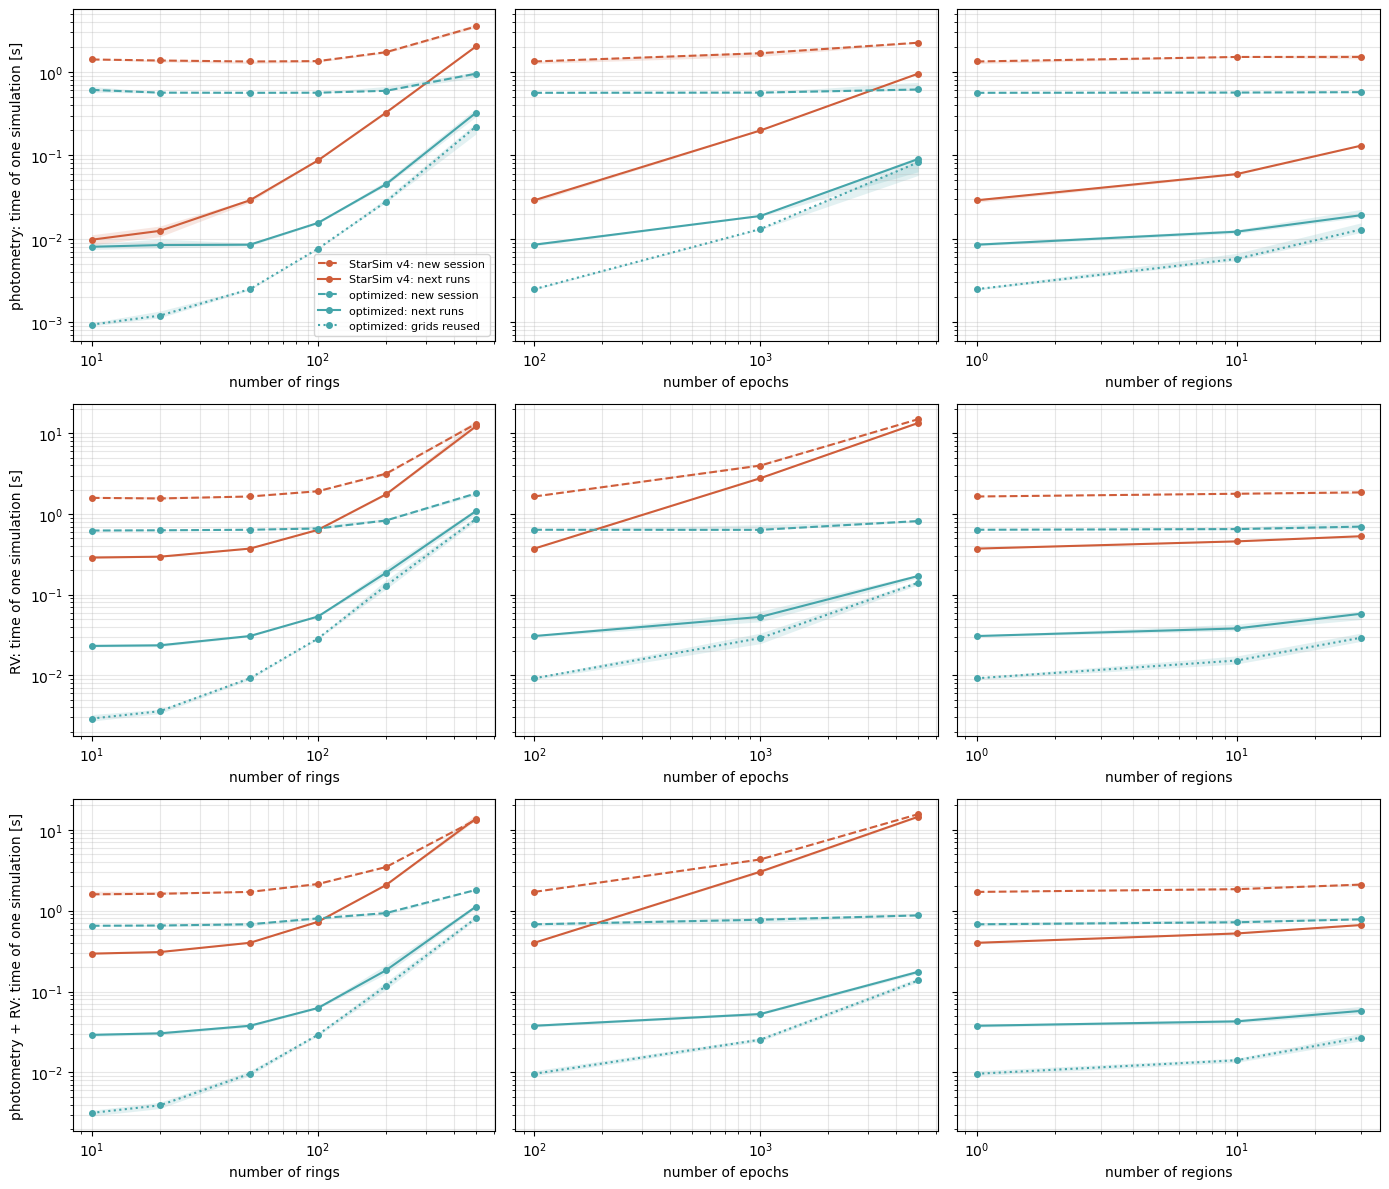

In [8]:
colors = {'StarSim v4': '#cf5d3a', 'optimized': '#45a5aa'}
labels = {'n_rings': 'number of rings', 'n_epochs': 'number of epochs', 'n_regions': 'number of regions'}

def sweep_rows(mode, key, version):
    others = [k for k in reference if k != key]
    d = summary[(summary['mode'] == mode) & (summary.version == version)
                & np.logical_and.reduce([summary[k] == reference[k] for k in others])]
    return d.sort_values(key)

fig, axes = plt.subplots(len(modes), 3, figsize=(14, 4 * len(modes)), sharey='row')
for i, mode in enumerate(modes):
    for j, key in enumerate(sweeps):
        ax = axes[i, j]
        for version in colors:
            d = sweep_rows(mode, key, version)
            series = [('new session [s]', '--o', 'new session'), ('next runs [s]', '-o', 'next runs')]
            if version == 'optimized':
                series.append(('grids reused [s]', ':o', 'grids reused'))
            for col, style, name in series:
                ax.plot(d[key], d[col], style, color=colors[version], ms=4, label='%s: %s' % (version, name))
                ax.fill_between(d[key], d['q25 ' + col], d['q75 ' + col], color=colors[version], alpha=0.15, lw=0)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel(labels[key])
        ax.grid(alpha=0.3, which='both')
    axes[i, 0].set_ylabel('%s: time of one simulation [s]' % mode_names[mode])
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Inside one simulation, reference case.** Time and memory of every step: first repetition (median over the processes) and next repetitions (median of all of them); for StarSim v4 everything is inside `init` and `simulate_forward`. The first repetition includes the start of Numba for SunSim, the import includes it for StarSim v4 (section 2). "RAM of the step" = peak during the step − memory before the step.

In [9]:
def steps_table(case):
    """Every step: first repetition (median over the processes) and next repetitions (median over all of them)."""
    groups = {}
    for r in runs:
        if any(r[k] != case[k] for k in case):
            continue
        for s in r['steps']:
            base, _, k = s['step'].rpartition(' ')
            if not k.isdigit():
                base, k = s['step'], '1'
            groups.setdefault((r['mode'], r['version'], base), []).append((int(k), s))
    rows = []
    for (mode, version, base), items in groups.items():
        first = [s for k, s in items if k == 1]
        nxt = [s for k, s in items if k > 1]
        rows.append({'mode': mode, 'version': version, 'step': base,
                     'first [s]': np.median([s['time [s]'] for s in first]),
                     'next (median) [s]': np.median([s['time [s]'] for s in nxt]) if nxt else np.nan,
                     'RAM of the step, first [MB]': np.median([s['rss peak [MB]'] - s['rss before [MB]'] for s in first]),
                     'RAM of the step, next (max) [MB]': max(s['rss peak [MB]'] - s['rss before [MB]'] for s in nxt) if nxt else np.nan})
    return pd.DataFrame(rows).set_index(['mode', 'version', 'step'])

steps_table(reference)

first [s]  next (median) [s]  \
mode version    step                                             
phot StarSim v4 import                 1.24                NaN   
                init                0.00203                NaN   
                simulate_forward     0.0813             0.0289   
     optimized  import                0.295                NaN   
                spectra              0.0187            0.00316   
                grids                  0.22            0.00284   
                simulation           0.0277            0.00249   
rv   StarSim v4 import                 1.16                NaN   
                init                0.00301                NaN   
                simulate_forward      0.482              0.372   
     optimized  import                0.299                NaN   
                spectra               0.263             0.0116   
                grids                0.0336               0.01   
                simulation           0.0423            0.00919   
both StarSim v4 import                 1.18                NaN   
                init                0.00385                NaN   
                simulate_forward      0.514                0.4   
     optimized  import                0.317                NaN   
                spectra               0.276             0.0148   
                grids                0.0389             0.0131   
                simulation           0.0434            0.00962   

                                  RAM of the step, first [MB]  \
mode version    step                                            
phot StarSim v4 import                                    155   
                init                                   0.0164   
                simulate_forward                         89.2   
     optimized  import                                   56.9   
                spectra                                  19.8   
                grids                                    39.8   
                simulation                                5.7   
rv   StarSim v4 import                                    154   
                init                                   0.0328   
                simulate_forward                          180   
     optimized  import                                   57.2   
                spectra                                  81.2   
                grids                                     9.4   
                simulation                               28.8   
both StarSim v4 import                                    154   
                init                                   0.0328   
                simulate_forward                          179   
     optimized  import                                   56.9   
                spectra                                  98.4   
                grids                                    9.86   
                simulation                               29.5   

                                  RAM of the step, next (max) [MB]  
mode version    step                                                
phot StarSim v4 import                                         NaN  
                init                                           NaN  
                simulate_forward                              37.1  
     optimized  import                                         NaN  
                spectra                                       11.2  
                grids                                         0.41  
                simulation                                   0.754  
rv   StarSim v4 import                                         NaN  
                init                                           NaN  
                simulate_forward                              64.2  
     optimized  import                                         NaN  
                spectra                                       17.8  
                grids                                

## 5. RAM

For every sweep and mode (medians over the processes): memory of the process after the imports, its peak during the run, and the difference (memory used by the simulations, compiled code included).

In [10]:
ram_columns = ['RAM after import [MB]', 'RAM peak [MB]', 'RAM for the simulations [MB]']
pd.options.display.float_format = '{:.0f}'.format
for mode in modes:
    for key in sweeps:
        print('\n%s, %s' % (mode_names[mode].upper(), key))
        display(side_by_side(mode, key, ram_columns))


PHOTOMETRY, n_rings


,StarSim v4,optimized,StarSim v4,optimized,StarSim v4,optimized
,RAM after import [MB],RAM after import [MB],RAM peak [MB],RAM peak [MB],RAM for the simulations [MB],RAM for the simulations [MB]
n_rings,,,,,,
10,212,115,404,231,191,116
20,212,114,431,239,219,124
50,212,114,448,236,237,123
100,211,114,418,254,205,141
200,212,114,460,287,249,173
500,213,115,538,658,325,543



PHOTOMETRY, n_epochs


,StarSim v4,optimized,StarSim v4,optimized,StarSim v4,optimized
,RAM after import [MB],RAM after import [MB],RAM peak [MB],RAM peak [MB],RAM for the simulations [MB],RAM for the simulations [MB]
n_epochs,,,,,,
100,212,114,448,236,237,123
1000,213,114,433,247,219,133
5000,211,115,427,237,213,122



PHOTOMETRY, n_regions


...

,StarSim v4,optimized,StarSim v4,optimized,StarSim v4,optimized
,RAM after import [MB],RAM after import [MB],RAM peak [MB],RAM peak [MB],RAM for the simulations [MB],RAM for the simulations [MB]
n_rings,,,,,,
10,210,114,493,373,282,259
20,211,114,538,373,328,260
50,211,114,551,379,341,265
100,211,114,687,468,476,353
200,212,115,1183,758,971,642
500,212,115,4777,784,4565,670



PHOTOMETRY + RV, n_epochs


,StarSim v4,optimized,StarSim v4,optimized,StarSim v4,optimized
,RAM after import [MB],RAM after import [MB],RAM peak [MB],RAM peak [MB],RAM for the simulations [MB],RAM for the simulations [MB]
n_epochs,,,,,,
100,211,114,551,379,341,265
1000,212,114,544,397,333,282
5000,211,114,495,443,284,329



PHOTOMETRY + RV, n_regions


,StarSim v4,optimized,StarSim v4,optimized,StarSim v4,optimized
,RAM after import [MB],RAM after import [MB],RAM peak [MB],RAM peak [MB],RAM for the simulations [MB],RAM for the simulations [MB]
n_regions,,,,,,
1,211,114,551,379,341,265
10,211,114,592,397,382,283
30,211,115,535,433,323,318


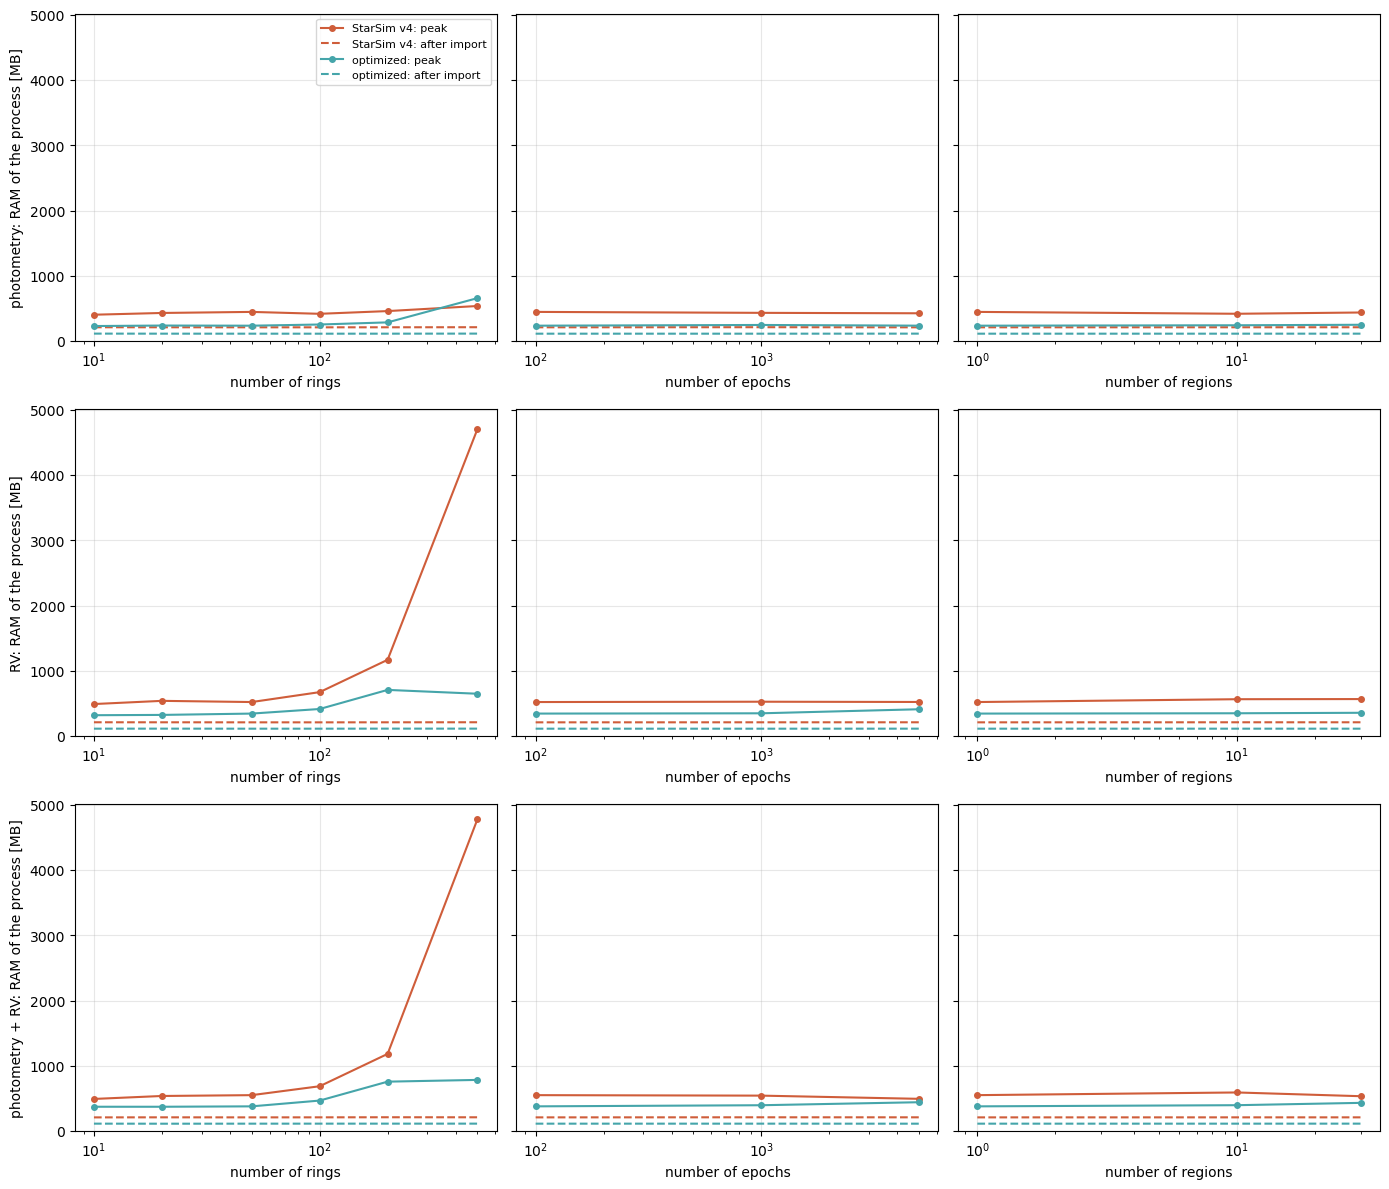

In [11]:
fig, axes = plt.subplots(len(modes), 3, figsize=(14, 4 * len(modes)), sharey=True)
for i, mode in enumerate(modes):
    for j, key in enumerate(sweeps):
        ax = axes[i, j]
        for version in colors:
            d = sweep_rows(mode, key, version)
            ax.plot(d[key], d['RAM peak [MB]'], '-o', color=colors[version], ms=4, label='%s: peak' % version)
            ax.plot(d[key], d['RAM after import [MB]'], '--', color=colors[version], label='%s: after import' % version)
        ax.set_xscale('log')
        ax.set_xlabel(labels[key])
        ax.grid(alpha=0.3)
    axes[i, 0].set_ylabel('%s: RAM of the process [MB]' % mode_names[mode])
axes[0, 0].set_ylim(0, 1.05 * summary['RAM peak [MB]'].max())   # shared by all the panels (sharey)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Outputs

A check that the two versions simulate the same thing: outputs of one simulation at every number of rings of `output_rings` (100 epochs, 1 region). Photometry: normalised flux and filling factors. RV: RV, FWHM and BIS relative to their median, contrast relative to its median.

The plot shows the finest grid (500 rings, ~635 000 cells). The table gives, for every number of rings, the amplitude (max − min) of every quantity in both versions and the largest difference between them, to see how the outputs and their agreement change with the resolution of the grid. The last table gives the time
and the peak RAM of these runs (one new session each, so one measurement, without the statistics of sections 4–5).

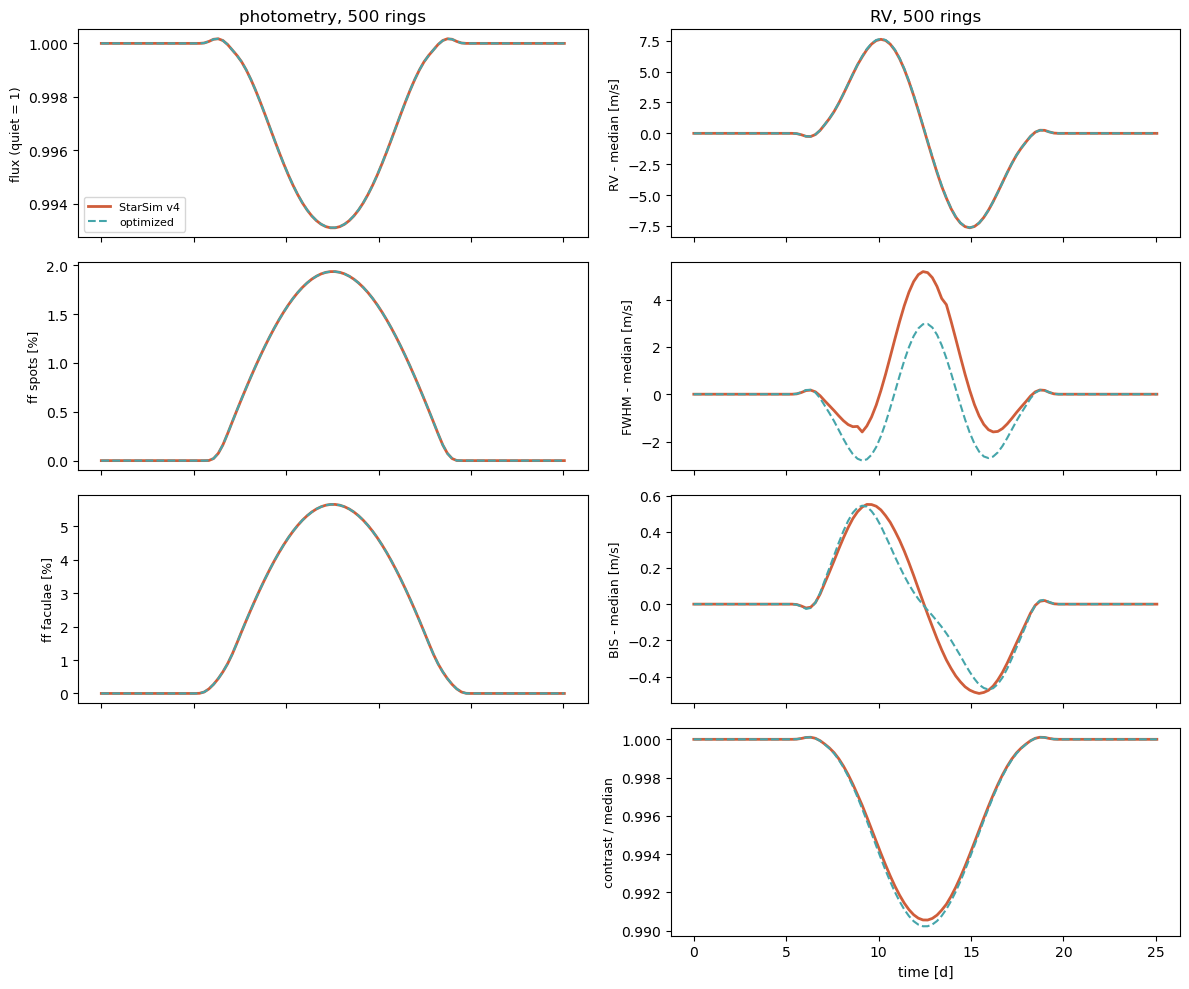

StarSim v4 (max - min)  optimized (max - min)  \
quantity            rings                                                  
flux (quiet = 1)    10                   0.008071               0.008066   
                    50                   0.007068                0.00706   
                    500                  0.007062               0.007055   
ff spots [%]        10                      2.218                  2.218   
                    50                      1.937                  1.937   
                    500                     1.936                  1.936   
ff faculae [%]      10                      5.733                  5.733   
                    50                      5.661                  5.661   
                    500                     5.658                  5.658   
RV - median [m/s]   10                      14.66                  14.69   
                    50                      15.22                  15.24   
                    500                     15.26                  15.29   
FWHM - median [m/s] 10                      7.461                  5.986   
                    50                      6.779                  5.774   
                    500                      6.78                   5.78   
BIS - median [m/s]  10                      1.098                  1.054   
                    50                      1.044                  1.015   
                    500                     1.044                  1.016   
contrast / median   10                    0.01093                0.01132   
                    50                   0.009563               0.009889   
                    500                  0.009556               0.009882   

                           max |v4 - optimized|  NaN in StarSim v4  
quantity            rings                                           
flux (quiet = 1)    10                4.587e-06                  0  
                    50                6.714e-06                  0  
                    500               6.736e-06                  0  
ff spots [%]        10                2.043e-14                  0  
                    50                1.044e-14                  0  
                    500               2.442e-15                  0  
ff faculae [%]      10                 1.51e-14                  0  
                    50                1.199e-14                  0  
                    500               6.217e-15                  0  
RV - median [m/s]   10                  0.05695                  0  
                    50                  0.06292                  0  
                    500                 0.06328                  0  
FWHM - median [m/s] 10                     2.77                  0  
                    50                    2.312                  0  
                    500                   2.325                  0  
BIS - median [m/s]  10                   0.1462                  0  
                    50                   0.1548                  0  
                    500                  0.1559                  0  
contrast / median   10                0.0003948                  0  
                    50                0.0003373                  0  
                    500               0.0003376                  0

RAM peak [MB]           new session [s]          
version       StarSim v4 optimized      StarSim v4 optimized
mode rings                                                  
phot 10              300       179            1.36     0.543
     50              299       180             1.2      0.54
     500             376       329            3.22     0.854
rv   10              369       210            1.51     0.604
     50              394       247             1.6      0.61
     500        2.57e+03       437            11.9       1.6

In [12]:
def outputs(mode, version, case=reference, source=None):
    """Outputs of the last simulation of the case: in `runs` (first process; reference case) by default, or in
    `source` (e.g. output_runs)."""
    source = runs if source is None else source
    return [r for r in source if r['mode'] == mode and r['version'] == version and 'outputs' in r
            and all(r[k] == case[k] for k in case)][0]['outputs']

rows = {'phot': [('flux', 'flux (quiet = 1)', 'abs'), ('ff_sp', 'ff spots [%]', 'abs'), ('ff_fc', 'ff faculae [%]', 'abs')],
        'rv': [('rv', 'RV - median [m/s]', 'median'), ('fwhm', 'FWHM - median [m/s]', 'median'),
               ('bis', 'BIS - median [m/s]', 'median'), ('contrast', 'contrast / median', 'ratio')]}

def compared(mode, key, how, case):
    """times, StarSim v4 and SunSim values of one output (relative to the median or as a ratio, see `how`)."""
    a_out, b_out = outputs(mode, 'StarSim v4', case, output_runs), outputs(mode, 'optimized', case, output_runs)
    a, b = np.asarray(a_out[key], dtype=float), np.asarray(b_out[key], dtype=float)
    if how == 'median':
        a, b = a - np.nanmedian(a), b - np.nanmedian(b)
    elif how == 'ratio':
        a, b = a / np.nanmedian(a), b / np.nanmedian(b)
    return a_out['times'], a, b

# plot: the finest grid
comparison_rings = max(output_rings)
comparison_case = dict(reference, n_rings=comparison_rings)
fig, axes = plt.subplots(4, 2, figsize=(12, 10), sharex=True)
for j, mode in enumerate(['phot', 'rv']):
    for i, (key, name, how) in enumerate(rows[mode]):
        t, a, b = compared(mode, key, how, comparison_case)
        ax = axes[i, j]
        ax.plot(t, a, '-', lw=2, color=colors['StarSim v4'], label='StarSim v4')
        ax.plot(t, b, '--', lw=1.5, color=colors['optimized'], label='optimized')
        ax.set_ylabel(name, fontsize=9)
    axes[-1, j].set_xlabel('time [d]')
    axes[0, j].set_title('%s, %d rings' % ({'phot': 'photometry', 'rv': 'RV'}[mode], comparison_rings))
axes[3, 0].axis('off')
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# table: every number of rings of output_rings
diffs = []
for n_rings in output_rings:
    case = dict(reference, n_rings=n_rings)
    for mode in ['phot', 'rv']:
        for key, name, how in rows[mode]:
            t, a, b = compared(mode, key, how, case)
            diffs.append({'quantity': name, 'rings': n_rings, 'StarSim v4 (max - min)': np.nanmax(a) - np.nanmin(a),
                          'optimized (max - min)': np.nanmax(b) - np.nanmin(b),
                          'max |v4 - optimized|': np.nanmax(np.abs(a - b)), 'NaN in StarSim v4': int(np.isnan(a).sum())})

pd.options.display.float_format = '{:.4g}'.format
order = [name for mode in ['phot', 'rv'] for _, name, _ in rows[mode]]
diffs = pd.DataFrame(diffs)
diffs['quantity'] = pd.Categorical(diffs['quantity'], order, ordered=True)
display(diffs.sort_values(['quantity', 'rings']).set_index(['quantity', 'rings']))

# time (import + first and only simulation: one new session) and peak RAM of these runs (one run each, no statistics)
cost = pd.DataFrame([{'mode': r['mode'], 'rings': r['n_rings'], 'version': r['version'],
                      'new session [s]': sum(s['time [s]'] for s in r['steps']), 'RAM peak [MB]': r['rss max process [MB]']}
                     for r in output_runs])
pd.options.display.float_format = '{:.3g}'.format
cost.pivot_table(index=['mode', 'rings'], columns='version', values=['new session [s]', 'RAM peak [MB]'])

**RAM with large grids.** At 500 rings the disc has ~635 000 cells. In RV both codes build the CCF of the star in the same way: the CCF of every cell is the CCF of its ring shifted by the rotation velocity of the cell, and at every epoch only the cells touched by a region change.

* **StarSim v4** computes the CCF of every cell once for the three surfaces (`_calculate_ccf` in `forward.py`) and keeps them: `ccf_cell_quiet`, `ccf_cell_spot`, `ccf_cell_facula`, three arrays of n_cells × n_rv (145 velocities), 0.74 GB each at 500 rings. The epochs are then done one after the other (`_spectroscopic_timeseries_core`). Peak: ~2.5 GB, ~12 s for 100 epochs.
* **SunSim** did the same (`loop_compute_immaculate_nb`), plus two things that StarSim v4 does not have, which made its peak higher (3.05 GB in RV, 657 MB in photometry against 372 MB):
  * every `flux_grid` kept the geometry of every cell (coordinates, rotation velocity), unused in photometry: now computed only when it is needed (spectroscopy with rotation);
  * the epochs run in parallel, and every epoch built full filling-factor arrays of the cells (4 × n_cells, on every thread): now every epoch keeps only the cells touched by a region or a planet (`_touched_cells_nb`: the same loop over the cells as `generate_ff_core`, written out, since a function called for every cell compiled ~3× slower), whose signals are then added in the same order.

  With these two changes (results bit for bit the same): ~300 MB in photometry and 2.64 GB in RV at 500 rings.
* **CCF of the cells on the fly.** The three arrays of cell CCFs are the rest. Above `ccf_cells_max_memory` (argument of `StarSim`, 512 MB by default: ~240 rings with 145 velocities), SunSim does not keep them: at every epoch it computes the CCF of the cells touched by a region (and only of the surfaces they have) from the CCF of their ring, with the same operations, and the CCF of the quiet star once, cell by cell. The outputs are bit for bit the same. At 500 rings: **448 MB** instead of 2.64 GB in RV, 3.2 s (StarSim v4: 2.5 GB, 12.4 s).
* **Cost.** The touched cells are interpolated again at every epoch instead of once. Measured (`generate_timeseries`, 1 region; time with the arrays kept / on the fly): 100 epochs: the same at all sizes (0.95 / 1.06 s at 500 rings); 1000 epochs: 1.4–1.9× slower (6.4 / 9.4 s at 500 rings); 5000 epochs: ~1.5× slower (31 / 48 s at 500 rings). Below the threshold the arrays are kept (fastest), and they take at most 512 MB. `ccf_cells_max_memory=None` keeps them always, `0` never.

### 6b. Photometry + RV: same outputs as the separate runs

For the reference case (first process), the outputs of the run that computes both are compared with those of the photometry run and of the RV run of the same version: largest absolute difference (0 = bit for bit the same).

In [13]:
rows_both = []
for version in ['StarSim v4', 'optimized']:
    both = outputs('both', version)
    for key, mode in (('flux', 'phot'), ('ff_sp', 'phot'), ('ff_fc', 'phot'), ('rv', 'rv'), ('fwhm', 'rv'),
                      ('bis', 'rv'), ('contrast', 'rv')):
        alone = outputs(mode, version)
        rows_both.append({'version': {'StarSim v4': 'StarSim v4', 'optimized': 'SunSim'}[version], 'output': key,
                          'max |both - separate|': np.nanmax(np.abs(np.asarray(both[key], dtype=float)
                                                                                 - np.asarray(alone[key], dtype=float)))})
pd.options.display.float_format = '{:.3g}'.format
pd.DataFrame(rows_both).pivot(index='output', columns='version')

max |both - separate|       
version             StarSim v4 SunSim
output                               
bis                          0      0
contrast                     0      0
ff_fc                        0      0
ff_sp                        0      0
flux                         0      0
fwhm                         0      0
rv                           0      0

### 6c. One spot alone and one facula alone

The same comparison for a single region (50 rings, `single_rings`; 100 epochs): a spot of 8° alone, and a facula of 16° alone (see `single_cases`). Photometry: flux and filling factors; RV: RV, FWHM and BIS relative to their median, contrast relative to its median. The FWHM, BIS and contrast are each code's own measurements (section 7.2 explains their differences).

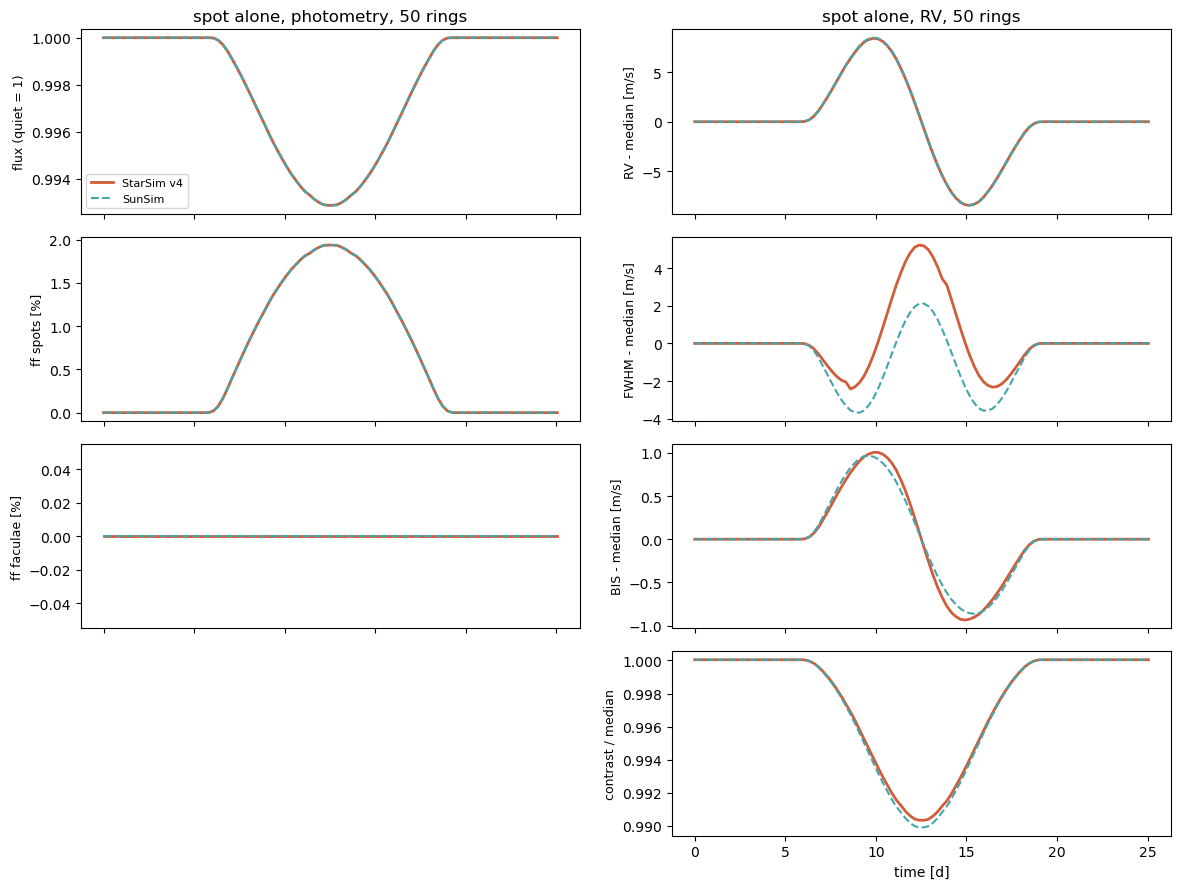

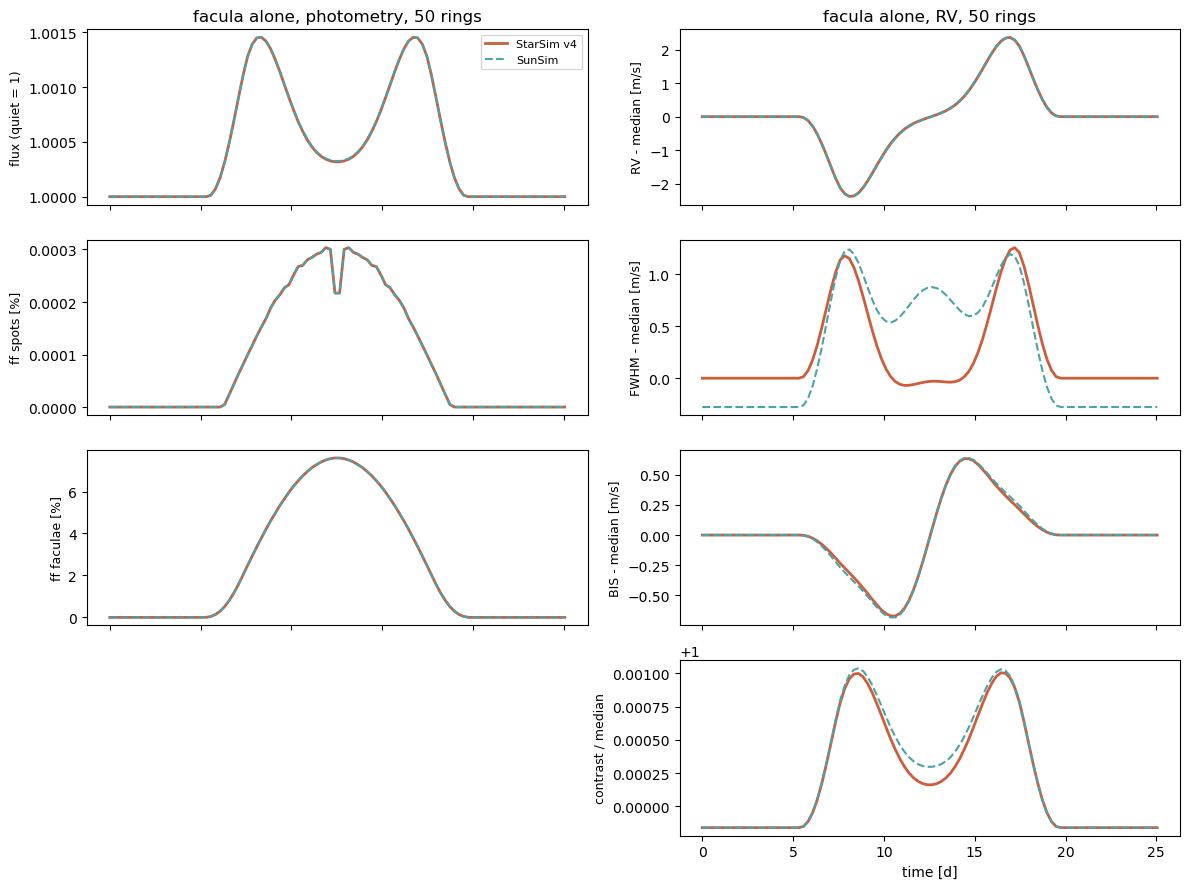

StarSim v4 (max - min)  SunSim (max - min)  \
region       quantity                                                          
spot alone   flux (quiet = 1)                   0.007139            0.007139   
             ff spots [%]                          1.937               1.937   
             ff faculae [%]                            0                   0   
             RV - median [m/s]                     16.87               16.93   
             FWHM - median [m/s]                   7.639               5.792   
             BIS - median [m/s]                    1.942                1.83   
             contrast / median                  0.009703             0.01013   
facula alone flux (quiet = 1)                   0.001455            0.001455   
             ff spots [%]                      0.0003035           0.0003035   
             ff faculae [%]                        7.598               7.598   
             RV - median [m/s]                     4.743               4.756   
             FWHM - median [m/s]                   1.324               1.515   
             BIS - median [m/s]                    1.302               1.319   
             contrast / median                  0.001166              0.0012   

                                  max |v4 - SunSim|  
region       quantity                                
spot alone   flux (quiet = 1)             1.665e-15  
             ff spots [%]                 1.044e-14  
             ff faculae [%]                       0  
             RV - median [m/s]              0.06492  
             FWHM - median [m/s]              3.156  
             BIS - median [m/s]              0.1534  
             contrast / median            0.0004343  
facula alone flux (quiet = 1)             7.536e-06  
             ff spots [%]                 7.997e-16  
             ff faculae [%]               6.217e-15  
             RV - median [m/s]              0.01919  
             FWHM - median [m/s]             0.9047  
             BIS - median [m/s]             0.03588  
             contrast / median            0.0001355

In [14]:
def single_outputs(name, mode, version):
    return [r for r in single_runs if r['single'] == name and r['mode'] == mode and r['version'] == version][0]['outputs']

rows_single = []
for name in single_cases:
    fig, axes = plt.subplots(4, 2, figsize=(12, 9), sharex=True)
    for j, mode in enumerate(['phot', 'rv']):
        a_out, b_out = single_outputs(name, mode, 'StarSim v4'), single_outputs(name, mode, 'optimized')
        for i, (key, label, how) in enumerate(rows[mode]):
            a, b = np.asarray(a_out[key], dtype=float), np.asarray(b_out[key], dtype=float)
            if how == 'median':
                a, b = a - np.nanmedian(a), b - np.nanmedian(b)
            elif how == 'ratio':
                a, b = a / np.nanmedian(a), b / np.nanmedian(b)
            ax = axes[i, j]
            ax.plot(a_out['times'], a, '-', lw=2, color=colors['StarSim v4'], label='StarSim v4')
            ax.plot(b_out['times'], b, '--', lw=1.5, color=colors['optimized'], label='SunSim')
            ax.set_ylabel(label, fontsize=9)
            rows_single.append({'region': name, 'quantity': label, 'StarSim v4 (max - min)': np.nanmax(a) - np.nanmin(a),
                                'SunSim (max - min)': np.nanmax(b) - np.nanmin(b), 'max |v4 - SunSim|': np.nanmax(np.abs(a - b))})
        axes[-1, j].set_xlabel('time [d]')
        axes[0, j].set_title('%s, %s, %d rings' % (name, {'phot': 'photometry', 'rv': 'RV'}[mode], single_rings))
    axes[3, 0].axis('off')
    axes[0, 0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

pd.options.display.float_format = '{:.4g}'.format
pd.DataFrame(rows_single).set_index(['region', 'quantity'])

## 7. Comparison of the CCFs

Section 6 compares the RV, FWHM, BIS and contrast that each code measures. Here the CCFs themselves are compared, to separate the CCFs from the way RV, FWHM and BIS are measured from them. The RV runs of the reference case save (last simulation):

* `ccf_centre_qp`, `ccf_centre_sp`, `ccf_centre_fc`: CCF of the spectrum of every surface (HiRes Phoenix spectrum × mask), before it is weighted by the brightness of the rings;
* `ccf_quiet_star`: CCF of the whole quiet star (all the cells, with their rotation, no region);
* `ccf`: CCF of the star at every epoch, on the velocity grid `ccf_rv`.

**Normalisation of the CCF of a spectrum.** Both versions compute −Σ weight × flux over the mask lines, a peak at the velocity of the lines, from the flattened spectrum. Here both normalise it in the same way, (ccf − min) / max(ccf − min): StarSim v4 always (`cross_correlation_mask_phoenix`), SunSim with `CCF_grid(..., normalization=True)` (`nbspectra.cross_correlation_mask`, `ccf_norm=True`). Every CCF goes from 0 to 1, whatever the depth of its lines. The SunSim default (`ccf_norm=False`) is 1 − ccf / min(ccf): the continuum at 0 and the height of the peak equal to the relative depth of the lines, so a surface with deeper lines has a higher CCF.

To compare their shapes, every CCF is also turned into a **normalised peak**: baseline (median of the 10 % of points at each end) at 0 and maximum at 1.

In [15]:
ccf_v4, ccf_ss = outputs('rv', 'StarSim v4'), outputs('rv', 'optimized')
rv_ccf = ccf_ss['ccf_rv']
assert np.allclose(ccf_v4['ccf_rv'], rv_ccf), 'the two versions use different velocity grids'
names = {'StarSim v4': 'StarSim v4', 'optimized': 'SunSim'}

def baseline_height(c, wing=0.1):
    """Baseline (median of the `wing` fraction of points at each end) and height (maximum - baseline) of a CCF peak."""
    n = max(1, int(len(c) * wing))
    base = np.median(np.concatenate((c[:n], c[-n:])))
    return base, np.max(c) - base

def normalised_peak(c):
    """CCF with the baseline at 0 and the maximum at 1."""
    c = np.asarray(c, dtype=float)
    base, height = baseline_height(c)
    return (c - base) / height

def gaussian(x, amp, mean, sigma, offset):
    return offset + amp * np.exp(-0.5 * ((x - mean) / sigma)**2)

def fit_peak(y):
    """Gaussian fit of a CCF peak on the whole velocity grid: centre [m/s], FWHM [m/s], amplitude."""
    from scipy.optimize import curve_fit
    p0 = [y.max() - np.median(y), rv_ccf[np.argmax(y)], 3000.0, np.median(y)]
    (amp, mean, sigma, offset), _ = curve_fit(gaussian, rv_ccf, y, p0=p0)
    return mean, 2 * np.sqrt(2 * np.log(2)) * abs(sigma), amp

### 7.1 CCF of the spectrum of every surface

Top: normalised peaks of both versions. Bottom: StarSim v4 − SunSim. The table gives, for every CCF, its centre and FWHM (same Gaussian fit for both versions) and the **height of the peak as each code computes it**. With the same normalisation it is close to 1 in both (a bit less, because the baseline used here, the median of the wings, is slightly above the minimum of the CCF).

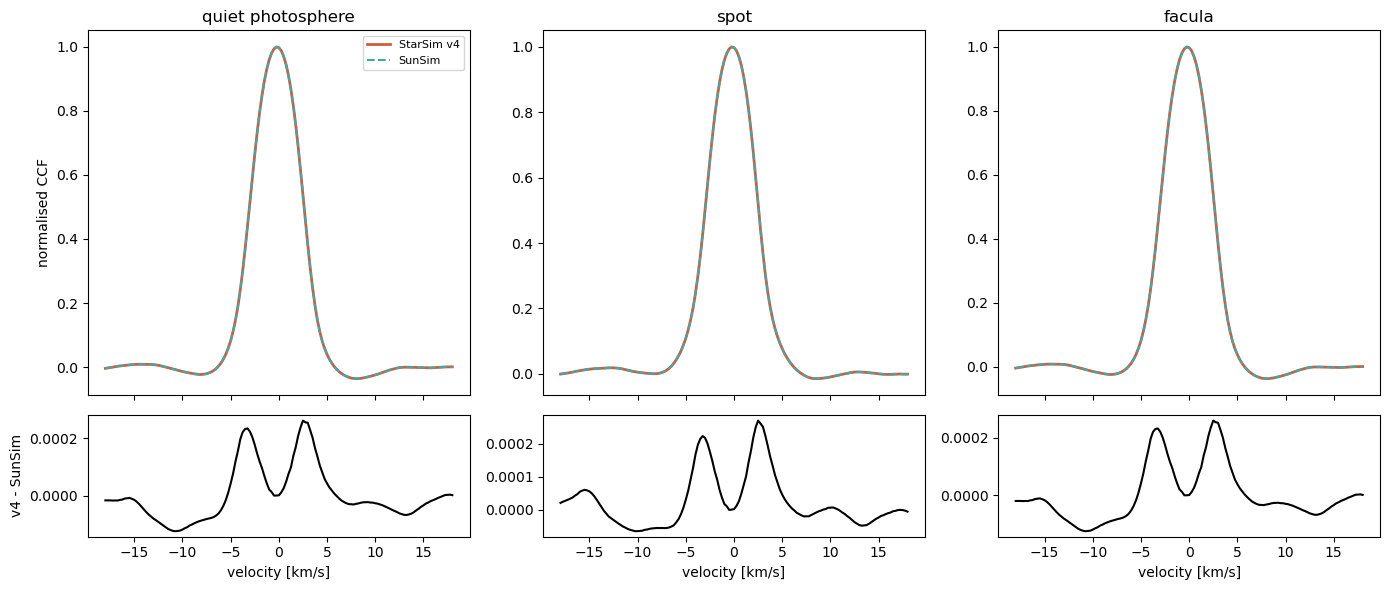

centre [m/s]  FWHM [m/s]  \
surface           version                                
quiet photosphere StarSim v4          -219        5376   
                  SunSim            -219.1        5374   
spot              StarSim v4        -215.6        5377   
                  SunSim            -215.7        5375   
facula            StarSim v4        -219.4        5381   
                  SunSim            -219.4        5380   

                              height of the peak (as computed)  
surface           version                                       
quiet photosphere StarSim v4                             0.965  
                  SunSim                                 0.965  
spot              StarSim v4                            0.9852  
                  SunSim                                0.9852  
facula            StarSim v4                             0.964  
                  SunSim                                0.9641

In [16]:
surfaces = [('ccf_centre_qp', 'quiet photosphere'), ('ccf_centre_sp', 'spot'), ('ccf_centre_fc', 'facula')]
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
rows_surf = []
for j, (key, title) in enumerate(surfaces):
    raw = {'StarSim v4': ccf_v4[key], 'optimized': ccf_ss[key]}
    y = {v: normalised_peak(raw[v]) for v in raw}
    for v in y:
        axes[0, j].plot(rv_ccf / 1000, y[v], color=colors[v], lw=2 if v == 'StarSim v4' else 1.5,
                        ls='-' if v == 'StarSim v4' else '--', label=names[v])
        centre, fwhm, _ = fit_peak(y[v])
        rows_surf.append({'surface': title, 'version': names[v], 'centre [m/s]': centre, 'FWHM [m/s]': fwhm,
                          'height of the peak (as computed)': baseline_height(raw[v])[1]})
    axes[1, j].plot(rv_ccf / 1000, y['StarSim v4'] - y['optimized'], color='k')
    axes[0, j].set_title(title)
    axes[1, j].set_xlabel('velocity [km/s]')
axes[0, 0].set_ylabel('normalised CCF')
axes[1, 0].set_ylabel('v4 - SunSim')
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.options.display.float_format = '{:.4g}'.format
pd.DataFrame(rows_surf).set_index(['surface', 'version'])

**Why the same flattening and normalisation.** With the SunSim defaults (raw Phoenix flux, `ccf_norm=False`) the CCFs of the surfaces differ from those of StarSim v4, for two reasons that have nothing to do with the simulation:

* **Shape (centre ≈ 2–5 m/s, FWHM ≈ 3–10 m/s): the flattening.** With raw flux, every mask line counts in proportion to the continuum around it, so lines in the bright part of the spectrum count more. The Phoenix lines are not exactly where the mask puts them (hence the common offset of about −215 m/s), so another weighting of the lines gives a slightly different centre and width. CCFs of the spectrum of every surface (same fit as above), computed once outside the benchmark:

| surface | SunSim raw: centre / FWHM [m/s] | SunSim flattened | StarSim v4 |
|---|---|---|---|
| quiet photosphere | −214.4 / 5385 | −219.1 / 5374 | −219.0 / 5376 |
| spot | −213.2 / 5380 | −215.7 / 5375 | −215.6 / 5377 |
| facula | −214.7 / 5390 | −219.4 / 5380 | −219.4 / 5381 |

  The remaining ≤ 2 m/s in FWHM come from the two continuum fits (polynomial in SunSim, spline in StarSim v4).
* **Height: the normalisation.** With `ccf_norm=False` the height is the relative depth of the lines: 0.55 for the quiet photosphere, 0.63 for the spot (cooler, deeper lines), 0.55 for the facula. StarSim v4 rescales every CCF to [0, 1], so it does not keep this difference, and the activity signal changes with it (by ~16 % in an earlier run with the SunSim defaults).

The CCF computation itself (`cross_correlation_mask` and `cross_correlation_mask_phoenix`) is the same algorithm in both codes.

### 7.2 Why the FWHM, BIS and contrast of the two codes differ

The CCFs of the two codes agree (7.1), and so does the RV, but the FWHM, BIS and contrast that each code measures from them do not. The two codes measure the CCF of every epoch with different conventions:

| | StarSim v4 (`compute_ccf_params`, `forward.py`) | SunSim (`ccf_params_nb`, `nbspectra.py`) |
|---|---|---|
| baseline subtracted | median of the outer 10 % of each wing | minimum of the CCF |
| window of the gaussian fit | cut for the CCF of **every epoch** (`fit_bis_ccf`) | cut for the **first** CCF, the same for all the epochs |
| offset C of the gaussian | bounded to [0, 2·10⁻⁶]: fixed at ~0 | free |
| bisector (BIS) | `fit_bis_ccf`, on the CCF normalised to its maximum | `speed_bisector_nb`, the same construction |

`measure` below reproduces both conventions with each choice apart (same gaussian, fitted with scipy), and is applied to the CCFs of both codes (reference case):

* the **check**: each code's own convention, applied to its own CCFs, gives its own output (first rows of the table);
* the **swap**: StarSim v4's convention applied to the CCFs of SunSim gives the FWHM of StarSim v4, and the reverse (plot): the difference is in the measurement, not in the CCFs;
* the **cause**, one choice at a time:
  * **offset fixed at ~0** (StarSim v4): the wings of a mask CCF are not gaussian, and without an offset to absorb them the width of the gaussian follows them: the FWHM amplitude is ~1 m/s larger, and depends on the baseline that was subtracted (with a free offset, the baseline makes no difference: the offset takes it);
  * **window of every epoch** (StarSim v4): when the asymmetry of the CCF moves a wing minimum by one velocity point (250 m/s), the window changes and the FWHM and contrast bend: this gives the kinks of the StarSim v4 curves (times printed below);
  * **BIS**: the two bisector constructions give the same bisector; the baseline changes the normalisation of the CCF, so the 10–40 % and 60–90 % heights of the BIS fall at other places of the line;
  * the **contrast** is the amplitude of the same gaussian: it changes with the offset and the window as the FWHM.

Neither convention is wrong, they measure the line differently. SunSim's does not depend on the estimate of the baseline and does not jump when the window would change.

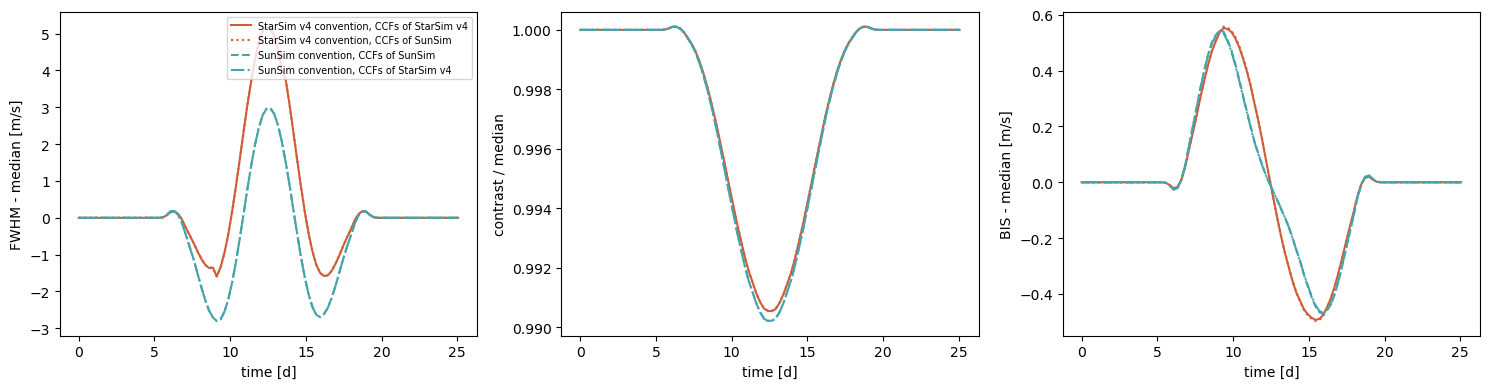

fit window of the StarSim v4 convention (indices on the velocity grid, step 250 m/s): (39, 107) at the first epoch; changes at t = 9.1 d (39, 108), 13.7 d (39, 107)


FWHM amplitude [m/s]  \
CCFs                                                 CCFs of StarSim v4   
convention                                                                
own output of the code                                            6.779   
SunSim convention                                                 5.773   
StarSim v4 convention                                             6.779   
baseline min, window first, offset free                           5.773   
baseline min, window first, offset fixed ~0                       6.622   
baseline min, window every epoch, offset free                     6.441   
baseline min, window every epoch, offset fixed ~0                 6.581   
baseline wing median, window first, offset free                   5.773   
baseline wing median, window first, offset fixe...                7.125   
baseline wing median, window every epoch, offse...                6.441   
baseline wing median, window every epoch, offse...                6.779   

                                                                   \
CCFs                                               CCFs of SunSim   
convention                                                          
own output of the code                                      5.774   
SunSim convention                                           5.774   
StarSim v4 convention                                       6.781   
baseline min, window first, offset free                     5.774   
baseline min, window first, offset fixed ~0                 6.626   
baseline min, window every epoch, offset free               6.416   
baseline min, window every epoch, offset fixed ~0           6.584   
baseline wing median, window first, offset free             5.774   
baseline wing median, window first, offset fixe...          7.127   
baseline wing median, window every epoch, offse...          6.416   
baseline wing median, window every epoch, offse...          6.781   

                                                   contrast / median amplitude  \
CCFs                                                        CCFs of StarSim v4   
convention                                                                       
own output of the code                                                0.009563   
SunSim convention                                                     0.009897   
StarSim v4 convention                                                 0.009563   
baseline min, window first, offset free                               0.009897   
baseline min, window first, offset fixed ~0                           0.009809   
baseline min, window every epoch, offset free                           0.0101   
baseline min, window every epoch, offset fixed ~0                     0.009806   
baseline wing median, window first, offset free                       0.009897   
baseline wing median, window first, offset fixe...                    0.009592   
baseline wing median, window every epoch, offse...                      0.0101   
baseline wing median, window every epoch, offse...                    0.009563   

                                                                   \
CCFs                                               CCFs of SunSim   
convention                                                          
own output of the code                                   0.009889   
SunSim convention                                        0.009889   
StarSim v4 convention                                    0.009556   
baseline min, window first, offset free                  0.009889   
baseline min, window first, offset fixed ~0              0.009802   
baseline min, window every epoch, offset free             0.01009   
baseline min, window every epoch, offset fixed ~0        0.009798   
baseline wing median, window first, offset free          0.009889   
baseline wing median, window first, offset fixe...       0.009584   
baseline wing median, window every epoch, offse...      

In [17]:
from scipy.optimize import curve_fit

times_ref = ccf_ss['times']
vsini_ref = 2 * np.pi * star['radius'] * 696342e3 / (star['P_rot'] * 86400)      # [m/s], equator-on

def wing_median(c, frac=0.1):
    n = max(1, int(len(c) * frac))
    return np.median(np.concatenate((c[:n], c[-n:])))

def bisector(rv, y):
    """Wing cuts and bisector of a CCF peak normalised to its maximum (construction of speed_bisector_nb and of
    fit_bis_ccf): 50 heights from 10 % above the higher wing minimum to 99 % of the maximum."""
    k = np.argmax(y); top, rv_top = y[k], rv[k]
    right = next((i for i in range(len(y)) if rv[i] > rv_top and y[i] > y[i - 1] and y[i] < 0.8 * top), len(y) - 1)
    left = next((j + 1 for j in range(len(y) - 2, -1, -1) if rv[j] < rv_top and y[j] > y[j + 1] and y[j] < 0.8 * top), 0)
    x, yy = rv[left:right], y[left:right]
    low = max(yy[x > rv_top].min(), yy[x < rv_top].min())
    ybis = np.linspace(low + 0.1 * (top - low), 0.99 * top, 50)
    xbis = np.empty(50)
    for n, h in enumerate(ybis):
        up = np.flatnonzero((yy[:-1] < h) & (yy[1:] > h) & (x[:-1] < rv_top))[-1]
        down = np.flatnonzero((yy[:-1] > h) & (yy[1:] < h) & (x[1:] > rv_top))[-1]
        r1 = x[up] + (x[up + 1] - x[up]) * (h - yy[up]) / (yy[up + 1] - yy[up])
        r2 = x[down] + (x[down + 1] - x[down]) * (h - yy[down]) / (yy[down + 1] - yy[down])
        xbis[n] = (r1 + r2) / 2
    return left, right, xbis, ybis

def measure(rv, ccfs, baseline, window, offset):
    """FWHM, contrast and BIS of every CCF with one convention: baseline 'min' or 'wing median'; window 'first'
    (cut for the first CCF) or 'every epoch'; offset of the gaussian 'free' or 'fixed ~0'. Also the fit windows."""
    shifted = [c - (c.min() if baseline == 'min' else wing_median(c)) + 1e-6 for c in ccfs]
    first_cut = bisector(rv, shifted[0] / shifted[0].max())[:2]
    fwhm, contrast, bis, windows = [], [], [], []
    for y in shifted:
        left, right, xbis, ybis = bisector(rv, y / y.max())
        if window == 'first':
            left, right = first_cut
        x, yy = rv[left:right], y[left:right]
        k = np.argmax(yy)
        if offset == 'free':
            p, _ = curve_fit(gaussian, x, yy, p0=[yy[k], x[k] + 100, 1.5 * vsini_ref + 1000, 1e-6], maxfev=20000)
        else:
            p, _ = curve_fit(gaussian, x, yy, p0=[yy[k], x[k], max(vsini_ref, 1000.0), 1e-6],
                             bounds=([0, rv[0], 0, 0], [2 * yy[k], rv[-1], rv[-1] - rv[0], 2e-6]))
        fwhm.append(2 * np.sqrt(2 * np.log(2)) * abs(p[2]))
        contrast.append(p[0])
        bis.append(np.mean(xbis[(ybis >= 0.1) & (ybis <= 0.4)]) - np.mean(xbis[(ybis >= 0.6) & (ybis <= 0.9)]))
        windows.append((left, right))
    return {'fwhm': np.array(fwhm), 'contrast': np.array(contrast), 'bis': np.array(bis), 'windows': np.array(windows)}

def amplitude(a):
    a = np.asarray(a, dtype=float)
    return np.nanmax(a) - np.nanmin(a)

conventions = {'SunSim convention': ('min', 'first', 'free'), 'StarSim v4 convention': ('wing median', 'every epoch', 'fixed ~0')}
for b in ('min', 'wing median'):
    for w in ('first', 'every epoch'):
        for o in ('free', 'fixed ~0'):
            conventions.setdefault('baseline %s, window %s, offset %s' % (b, w, o), (b, w, o))

ccf_sets = {'CCFs of SunSim': ccf_ss, 'CCFs of StarSim v4': ccf_v4}
results, rows_conv = {}, []
for set_name, out in ccf_sets.items():
    rows_conv.append({'convention': 'own output of the code', 'CCFs': set_name, 'FWHM amplitude [m/s]': amplitude(out['fwhm']),
                      'contrast / median amplitude': amplitude(out['contrast'] / np.nanmedian(out['contrast'])),
                      'BIS amplitude [m/s]': amplitude(out['bis'])})
    for name, conv in conventions.items():
        r = measure(rv_ccf, out['ccf'], *conv)
        results[(set_name, name)] = r
        rows_conv.append({'convention': name, 'CCFs': set_name, 'FWHM amplitude [m/s]': amplitude(r['fwhm']),
                          'contrast / median amplitude': amplitude(r['contrast'] / np.median(r['contrast'])),
                          'BIS amplitude [m/s]': amplitude(r['bis'])})

# the swap: each convention applied to the CCFs of the other code
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, key, label in zip(axes, ['fwhm', 'contrast', 'bis'], ['FWHM - median [m/s]', 'contrast / median', 'BIS - median [m/s]']):
    for (set_name, conv), style in ((('CCFs of StarSim v4', 'StarSim v4 convention'), '-'), (('CCFs of SunSim', 'StarSim v4 convention'), ':'),
                                    (('CCFs of SunSim', 'SunSim convention'), '--'), (('CCFs of StarSim v4', 'SunSim convention'), '-.')):
        v = results[(set_name, conv)][key]
        v = v / np.median(v) if key == 'contrast' else v - np.median(v)
        ax.plot(times_ref, v, style, color=colors['StarSim v4' if conv.startswith('StarSim') else 'optimized'], lw=1.5,
                label='%s, %s' % (conv, set_name))
    ax.set_xlabel('time [d]')
    ax.set_ylabel(label)
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

w = results[('CCFs of StarSim v4', 'StarSim v4 convention')]['windows']
changes = np.flatnonzero(np.any(np.diff(w, axis=0) != 0, axis=1)) + 1
print('fit window of the StarSim v4 convention (indices on the velocity grid, step %.0f m/s): %s at the first epoch; '
      'changes at t = %s' % (rv_ccf[1] - rv_ccf[0], tuple(w[0]), ', '.join('%.1f d %s' % (times_ref[k], tuple(w[k])) for k in changes) or 'none'))
pd.options.display.float_format = '{:.4g}'.format
pd.DataFrame(rows_conv).pivot(index='convention', columns='CCFs').reindex(['own output of the code'] + list(conventions))

## 8. Summary

Medians of this run (the ranges cover all the cases of the sweeps; the speed-up is StarSim v4 / SunSim). The import and the first run alone are given for information: the cold time to compare is the new session (section 2).

In [18]:
def ranges(d, col):
    return '%.3g–%.3g' % (d[col].min(), d[col].max())

rows_s = []
for mode, mode_name in mode_names.items():
    a = summary[(summary['mode'] == mode) & (summary.version == 'StarSim v4')].set_index(['n_rings', 'n_epochs', 'n_regions'])
    b = summary[(summary['mode'] == mode) & (summary.version == 'optimized')].set_index(['n_rings', 'n_epochs', 'n_regions'])
    for col in ['new session [s]', 'import [s]', 'first run [s]', 'next runs [s]', 'grids reused [s]',
                'RAM after import [MB]', 'RAM peak [MB]', 'RAM for the simulations [MB]']:
        row = {'mode': mode_name, 'quantity': col, 'StarSim v4': ranges(a, col) if a[col].notna().all() else '—',
               'SunSim': ranges(b, col)}
        if col in ('new session [s]', 'next runs [s]', 'grids reused [s]'):
            ref = a['next runs [s]'] if col == 'grids reused [s]' else a[col]
            row['speed-up'] = '%.3g–%.3g×' % ((ref / b[col]).min(), (ref / b[col]).max())
        elif col == 'RAM peak [MB]':
            row['SunSim − StarSim v4'] = '%.0f to %.0f MB' % ((b[col] - a[col]).min(), (b[col] - a[col]).max())
        rows_s.append(row)
pd.DataFrame(rows_s).set_index(['mode', 'quantity']).fillna('')

StarSim v4          SunSim  \
mode            quantity                                                     
photometry      new session [s]                   1.33–3.5     0.561–0.951   
                import [s]                        1.2–1.41     0.282–0.342   
                first run [s]                   0.0706–2.1     0.267–0.609   
                next runs [s]                 0.00976–2.01   0.00803–0.323   
                grids reused [s]                         —  0.000939–0.221   
                RAM after import [MB]              211–213         114–115   
                RAM peak [MB]                      404–538         231–658   
                RAM for the simulations [MB]       191–325         116–543   
RV              new session [s]                    1.56–15       0.624–1.8   
                import [s]                       1.14–1.39     0.286–0.368   
                first run [s]                   0.401–13.8      0.337–1.43   
                next runs [s]                   0.288–13.5     0.0231–1.09   
                grids reused [s]                         —   0.00291–0.868   
                RAM after import [MB]              211–212         114–115   
                RAM peak [MB]                  491–4.7e+03         320–708   
                RAM for the simulations [MB]  279–4.49e+03         206–593   
photometry + RV new session [s]                  1.59–15.6        0.65–1.8   
                import [s]                       1.17–1.31     0.292–0.368   
                first run [s]                   0.422–14.3      0.357–1.44   
                next runs [s]                   0.294–14.5     0.0291–1.12   
                grids reused [s]                         —   0.00316–0.807   
                RAM after import [MB]              210–212         114–115   
                RAM peak [MB]                 493–4.78e+03         373–784   
                RAM for the simulations [MB]  282–4.57e+03         259–670   

                                                speed-up SunSim − StarSim v4  
mode            quantity                                                      
photometry      new session [s]               2.31–3.68×                      
                import [s]                                                    
                first run [s]                                                 
                next runs [s]                 1.21–10.6×                      
                grids reused [s]               9.1–15.2×                      
                RAM after import [MB]                                         
                RAM peak [MB]                                 -211 to 121 MB  
                RAM for the simulations [MB]                                  
RV              new session [s]               2.48–18.3×                      
                import [s]                                                    
                first run [s]                                                 
                next runs [s]                   9.15–79×                      
                grids reused [s]              13.6–99.3×                      
                RAM after import [MB]                                         
                RAM peak [MB]                               -4054 to -111 MB  
                RAM for the simulations [MB]                                  
photometry + RV new session [s]               2.45–17.9×                      
                import [s]                                                    
                first run [s]                                                 
                next runs [s]                 10.1–82.8×                      
                grids reused [s]                 17–119×                      
                RAM after import [MB]                                         
                RAM peak [MB]                                -3992 to -52 MB  
                RAM for the simulations [MB]

* **Machine.** This run (reference case: 50 rings; rings swept from 10 to 500) was made while the machine was busier than for earlier runs: the absolute times of both codes are ~2× longer, the ratios are what matters.
* **New session (import + first run).** SunSim is 2.2× faster in photometry (0.57 s against 1.24 s, reference case), 2.5× in RV (0.65 s against 1.64 s) and 2.7× for photometry + RV (0.65 s against 1.73 s); up to 4× in photometry and 7× in RV with 500 rings, 19× in RV with 5000 epochs. Both codes start Numba once per process (~0.1–0.2 s): StarSim v4 in `import starsim` (1.2 s in all), SunSim in its first run (after a 0.3 s import). So the first run alone of StarSim v4 looks faster in photometry, but its import costs much more.
* **Next runs, photometry.** SunSim is faster in all the cases: 3.1× in the reference case (8.7 ms against 27 ms), the same with 10 rings, 6–8× from 100 to 500 rings (0.25 s against 2.0 s at 500 rings), 11× with 1000–5000 epochs.
* **Next runs, RV.** SunSim is 12× faster in the reference case (30 ms against 368 ms), 11–13× at every number of rings up to 500 (0.9 s against 11 s), and its time hardly grows with the number of epochs (47 ms for 1000, 152 ms for 5000) while that of StarSim v4 does (2.8 s, 13.5 s): 59× and 89× faster.
* **Photometry + RV.** SunSim computes both in one simulation (the geometry and the filling factors once): 36 ms per next run against 399 ms for StarSim v4 (11×; up to 95× with 5000 epochs, 13× at 500 rings). Computing both costs SunSim little more than RV alone (36 ms against 30 ms), as for StarSim v4 (399 ms against 368 ms), whose photometry is cheap next to its RV. The outputs are exactly those of the separate runs in both codes (section 6b).
* **Grids reused.** When only the regions, epochs or planets change, SunSim only redoes `simulation`: 0.9 ms–0.16 s in photometry, 3 ms–0.7 s in RV, i.e. 9–15× and 16–113× faster than a StarSim v4 run. StarSim v4 cannot reuse its grids.
* **Spread.** The 25th and 75th percentiles are within a few % of the medians (section 4, reference case): with 5 processes and up to 100 repetitions per case, the differences between the codes are well above the noise.
* **RAM.** Much of the memory is the libraries and the compiled Numba code: ~114 MB after import for SunSim against ~211 MB. In RV SunSim needs less in all the cases (peak 354 vs 568 MB in the reference case; 0.73 vs 4.7 GB at 500 rings, as StarSim v4 keeps the CCF of every cell of the 3 surfaces, ~4.5 GB, while SunSim computes them on the fly above `ccf_cells_max_memory`). In photometry SunSim needs less up to 200 rings (250 vs 376 MB in the reference case), but 80 MB more at 500 rings in the sweeps (586 vs 505 MB peak; 300 vs 375 MB in the single run of section 6): the grids of the 3 surfaces and their repetitions are kept in memory.
* **Large grids (section 6).** At 500 rings (~635 000 cells, one run each): photometry 0.80 s and 300 MB for SunSim against 3.2 s and 375 MB; RV 1.6 s and 428 MB against 10.4 s and 2.7 GB.
* **Outputs (sections 6 and 7).** Both take the Phoenix SPECINT spectra in the same way (rows of models with different μ added without interpolation, every surface at the μ of the first photosphere model). In photometry the two versions agree: a spot alone to rounding (2e-15 in flux), filling factors to 1e-14, and the flux of the reference spot + facula to ~7e-6 at 10, 50 and 500 rings (the faculae: ~8e-6 with a facula alone, section 6c). In RV, with the same flattening and CCF normalisation, their CCFs agree (section 7.1), and so do their RV (to 0.06 m/s). The FWHM, BIS and contrast that each code measures differ (FWHM amplitude ~1 m/s larger in StarSim v4 with the reference spot + facula, ~1.8 m/s with a spot alone, ~0.2 m/s smaller with a facula alone, section 6c): section 7.2 shows that this comes from the way they are measured (StarSim v4: offset of the gaussian fixed at ~0 after subtracting the median of the wings, and a fit window cut for every epoch; SunSim: free offset and the window of the first CCF), not from the CCFs: each convention gives the same values on the CCFs of either code.
* **Limits.** One machine (10 Numba threads), the same for both codes. The absolute times depend on the state of the machine (this execution gave times ~2× longer than an earlier one for both codes, with similar ratios). The RSS counts everything the process holds, including memory that the allocator keeps after freeing it.

## 9. Improvement of SunSim over StarSim v4

One table with the gain of SunSim for every quantity. Time: speed-up = time of StarSim v4 / time of SunSim (for *grids reused*, the reference is a full `simulate_forward` of StarSim v4, which cannot reuse its grids). RAM: memory saved = StarSim v4 − SunSim, in MB and in % of StarSim v4. The values are the medians for the reference case (50 rings, 100 epochs, 1 region) and the range over all the cases of the sweeps.

In [19]:
keys = ['n_rings', 'n_epochs', 'n_regions']
ref_index = tuple(reference[k] for k in keys)

def ratio(x):
    return '%.2g' % x if x < 100 else '%.0f' % x

def speed(g):
    return '%s× faster' % ratio(g) if g >= 1 else '%s× slower' % ratio(1 / g)

def memory(saved, pct):
    return '%.0f MB less (%.0f %%)' % (saved, pct) if saved >= 0 else '%.0f MB more (%.0f %%)' % (-saved, -pct)

rows_imp = []
for mode, mode_name in mode_names.items():
    a = summary[(summary['mode'] == mode) & (summary.version == 'StarSim v4')].set_index(keys)
    b = summary[(summary['mode'] == mode) & (summary.version == 'optimized')].set_index(keys)
    for col, name in (('new session [s]', 'time: new session (import + first run)'),
                      ('next runs [s]', 'time: next runs (same session)'), ('grids reused [s]', 'time: grids reused')):
        ref = a['next runs [s]'] if col == 'grids reused [s]' else a[col]
        gain = ref / b[col]
        rows_imp.append({'mode': mode_name, 'quantity': name,
                         'StarSim v4 (reference)': '%.3g s' % ref[ref_index], 'SunSim (reference)': '%.3g s' % b[col][ref_index],
                         'SunSim vs StarSim v4 (reference)': speed(gain[ref_index]),
                         'SunSim vs StarSim v4 (all cases)': speed(gain.min()) if gain.min() == gain.max()
                                                              else '%s to %s' % (speed(gain.min()), speed(gain.max()))})
    for col, name in (('RAM peak [MB]', 'RAM: peak of the process'), ('RAM for the simulations [MB]', 'RAM: for the simulations')):
        saved = a[col] - b[col]
        pct = 100 * saved / a[col]
        rows_imp.append({'mode': mode_name, 'quantity': name,
                         'StarSim v4 (reference)': '%.0f MB' % a[col][ref_index], 'SunSim (reference)': '%.0f MB' % b[col][ref_index],
                         'SunSim vs StarSim v4 (reference)': memory(saved[ref_index], pct[ref_index]),
                         'SunSim vs StarSim v4 (all cases)': '%s to %s' % (memory(saved.min(), pct.min()), memory(saved.max(), pct.max()))})
improvement = pd.DataFrame(rows_imp).set_index(['mode', 'quantity'])
improvement

StarSim v4 (reference)  \
mode            quantity                                                        
photometry      time: new session (import + first run)                 1.33 s   
                time: next runs (same session)                       0.0289 s   
                time: grids reused                                   0.0289 s   
                RAM: peak of the process                               448 MB   
                RAM: for the simulations                               237 MB   
RV              time: new session (import + first run)                 1.65 s   
                time: next runs (same session)                        0.372 s   
                time: grids reused                                    0.372 s   
                RAM: peak of the process                               522 MB   
                RAM: for the simulations                               312 MB   
photometry + RV time: new session (import + first run)                  1.7 s   
                time: next runs (same session)                          0.4 s   
                time: grids reused                                      0.4 s   
                RAM: peak of the process                               551 MB   
                RAM: for the simulations                               341 MB   

                                                       SunSim (reference)  \
mode            quantity                                                    
photometry      time: new session (import + first run)            0.561 s   
                time: next runs (same session)                   0.0085 s   
                time: grids reused                              0.00249 s   
                RAM: peak of the process                           236 MB   
                RAM: for the simulations                           123 MB   
RV              time: new session (import + first run)            0.638 s   
                time: next runs (same session)                   0.0307 s   
                time: grids reused                              0.00919 s   
                RAM: peak of the process                           345 MB   
                RAM: for the simulations                           232 MB   
photometry + RV time: new session (import + first run)            0.677 s   
                time: next runs (same session)                   0.0377 s   
                time: grids reused                              0.00962 s   
                RAM: peak of the process                           379 MB   
                RAM: for the simulations                           265 MB   

                                                       SunSim vs StarSim v4 (reference)  \
mode            quantity                                                                  
photometry      time: new session (import + first run)                      2.4× faster   
                time: next runs (same session)                              3.4× faster   
                time: grids reused                                           12× faster   
                RAM: peak of the process                             211 MB less (47 %)   
                RAM: for the simulations                             114 MB less (48 %)   
RV              time: new session (import + first run)                      2.6× faster   
                time: next runs (same session)                               12× faster   
                time: grids reused                                           41× faster   
                RAM: peak of the process                             177 MB less (34 %)   
                RAM: for the simulations                              80 MB less (26 %)   
photometry + RV time: new session (import + first run)                      2.5× faster   
                time: next runs (same session)                               11× faster   
                time: grids reused                                           42× faster   
  

## 11. Instrumental effect: CCFs order by order, StarSim v4 vs SunSim

Both codes can compute the CCFs **order by order** for a spectrograph. Here both use the **same orders, blaze and efficiency** — the 72 orders and the blaze of the HARPS files installed with SunSim (`sunsim.INSTRUMENTS_DIR`) and the total efficiency of HARPS-N — and the **same resolution** (R = 110 000, the value of StarSim v4 for `harps-n`).

**StarSim v4: echelle mode** (`simulate_forward(times, ['echelle'])`, `[FLAGS] flag_blaze = 1`, `[INSTRUMENT] order_data_file`)

* **Orders and blaze.** `response.load_order_response` reads a pickle file of five records: number of orders, number of pixels, an unused array, the wavelengths of the pixels of every order and the *instrumental response* of every order (n_orders × n_pixels). The repository has no such file (its `harps-blazes.bin`, `espresso-blazes.bin`, ... are not included), so it is written here from the HARPS files of SunSim, in the work folder (an absolute path in `order_data_file`; StarSim v4 is not modified).
* **Efficiency.** StarSim v4 has **no separate efficiency**: the *response* of every order is the whole instrumental response, and every pixel is multiplied by it. The efficiency of HARPS-N is therefore put in it: response = blaze × efficiency (efficiency interpolated at the wavelength of every pixel). This is the same product as SunSim's `blaze × instrumental_efficiency`.
* **For every order**: the Phoenix spectra of the order range are read, interpolated in temperature and log g and flattened (continuum of the order); interpolated **linearly** (`np.interp`) on the pixels of the order and multiplied by the response; **then** degraded to the resolution of the instrument (on the pixels of the order); the CCF of every surface is the cross-correlation with the **synthetic spectrum itself** (template: the quiet spectrum × response, not degraded) — the echelle mode always uses this template, never the line mask (`FLAG_TEMPLATE = 0`; its mask CCF finds the pixels from the steps of the Phoenix grid, so it could not be used on the pixels of an order); then a whole simulation (rings, regions, Doppler shifts) and the fit of the CCFs.
* **Outputs**: RV, FWHM, BIS and contrast **of every order** (n_epochs × n_orders), the chromatic indices (slopes against log λ), and the CCFs of every order. There is no CCF of all the orders together.

**SunSim** (`CCF_grid(..., instrument=110000, blaze_function=(wavelengths, blaze), instrumental_efficiency=(λ, efficiency))`)

* **For every spectrum** (the 3 surfaces): degraded to the resolution of the instrument **first** (whole spectrum); resampled on the pixels of every order **conserving the flux**; multiplied by blaze × efficiency; CCF of every order with the **line mask** (the lines inside the order); **sum of the orders**: one CCF per ring, then one simulation and one fit.
* **Outputs**: RV, FWHM, BIS, contrast of the CCF of all the orders together. For the comparison below, every order is also simulated alone (a separate run, not timed: each order with its own CCF grids).

**Runs** (reference case: 50 rings, 100 epochs, one spot with its facula; 3 new processes per version; 3 simulations per process, as StarSim v4 takes ~30 s per simulation here):

| version | runs |
|---|---|
| StarSim v4, echelle | `simulate_forward(times, ['echelle'])`: 72 orders, response = blaze × efficiency, `instrument = harps-n` (R = 110 000) |
| SunSim, order by order | 72 orders, blaze × efficiency, R = 110 000; CCF of the sum of the orders |

In [20]:
import pickle
import sunsim
from astropy.io import fits

# orders, blaze and efficiency of the HARPS / HARPS-N files installed with SunSim
D = sunsim.INSTRUMENTS_DIR
order_wav = fits.getdata(D / 'HARPS.2024-10-17T21-57-53.302_wave_A.fits').astype(np.float64)       # (72, 4096) [A]
order_blaze = fits.getdata(D / 'HARPS.2025-12-16T23-21-06.037_blaze_A.fits').astype(np.float64)
eff_table = np.genfromtxt(D / 'HARPS-N_total_efficiency.csv', delimiter=',', names=True)
eff_wav, eff_val = 10 * eff_table[eff_table.dtype.names[0]], eff_table[eff_table.dtype.names[1]] / 100   # nm -> A, % -> 1
order_eff = np.interp(order_wav, eff_wav[np.argsort(eff_wav)], eff_val[np.argsort(eff_wav)])
order_response = order_blaze * order_eff                        # the response of StarSim v4: blaze x efficiency

# response file of StarSim v4 (five pickle records: n_orders, n_pixels, unused array, wavelengths, response)
response_file = os.path.join(work_dir, 'harps_orders_blaze_x_harpsn_efficiency.bin')
with open(response_file, 'wb') as f:
    for record in (order_wav.shape[0], order_wav.shape[1], np.zeros(1), order_wav, order_response):
        pickle.dump(record, f)
print('%d orders of %d pixels, %.0f-%.0f A; response file: %s' % (order_wav.shape + (order_wav.min(), order_wav.max(), response_file)))

echelle_variants = {                       # name: (version, settings of the run)
    'StarSim v4, echelle': ('StarSim v4', {'v4_echelle': response_file, 'v4_instrument': 'harps-n'}),
    'SunSim, order by order': ('optimized', {'opt_instrument': 'harpsn_orders', 'opt_R': 110000,
                                             'orders_range': [float(order_wav.min()), float(order_wav.max())]}),
}
n_processes_echelle = 3
echelle_runs = []
t0 = time.perf_counter()
for process in range(n_processes_echelle):
    for k, (name, (version, override)) in enumerate(echelle_variants.items()):
        r = run(version, 'rv', reference, process=300 + 10 * k + process, keep_outputs=(process == 0),
                n_next=2, min_next=2, max_warm_seconds=0, **override)
        r['variant'] = name
        echelle_runs.append(r)
    print('processes %d/%d done (%.1f min)' % (process + 1, n_processes_echelle, (time.perf_counter() - t0) / 60))

# SunSim, every order alone (not timed; its own process, so that the measurements above are not affected)
t0 = time.perf_counter()
per_order_run = run('optimized', 'rv', reference, process=399, keep_outputs=True, n_next=0, min_next=0,
                    per_order=True, **echelle_variants['SunSim, order by order'][1])
print('SunSim, every order alone: %.1f min' % ((time.perf_counter() - t0) / 60))

72 orders of 4096 pixels, 3780-6913 A; response file: /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim4_gzd8g7dq/harps_orders_blaze_x_harpsn_efficiency.bin


processes 1/3 done (1.6 min)


processes 2/3 done (3.1 min)


processes 3/3 done (4.5 min)


SunSim, every order alone: 0.1 min


In [21]:
def echelle_process(r):
    # time and RAM of one process (the definitions of sections 4-5)
    st = {s['step']: s for s in r['steps']}
    if r['version'] == 'StarSim v4':
        reps = [[st[k]] for k in st if k.startswith('simulate_forward')]
        first = st['init']['time [s]'] + reps[0][0]['time [s]']
        reused = []                                 # StarSim v4 recomputes the orders in every simulate_forward
    else:
        n = sum(k.startswith('simulation') for k in st)
        reps = [[st['%s %d' % (step, k)] for step in ('spectra', 'grids', 'simulation')] for k in range(1, n + 1)]
        first = sum(s['time [s]'] for s in reps[0])
        reused = [rep[2]['time [s]'] for rep in reps[1:]]   # simulation alone, the CCF grids of the orders reused
    return {'variant': r['variant'], 'new session [s]': st['import']['time [s]'] + first,
            'next': [sum(s['time [s]'] for s in rep) for rep in reps[1:]], 'reused': reused,
            'RAM peak [MB]': r['rss max process [MB]'],
            'RAM for the simulations [MB]': r['rss max process [MB]'] - st['import']['rss after [MB]']}

ep = pd.DataFrame([echelle_process(r) for r in echelle_runs])
rows = []
for name in echelle_variants:
    d = ep[ep.variant == name]
    nxt, reused = np.concatenate(d['next'].values), np.concatenate(d['reused'].values)
    rows.append({'version': name, 'new session [s]': d['new session [s]'].median(),
                 'next runs [s]': np.median(nxt), 'next runs, min-max [s]': '%.2f-%.2f' % (nxt.min(), nxt.max()),
                 'grids reused [s]': np.median(reused) if len(reused) else np.nan,
                 'RAM peak [MB]': d['RAM peak [MB]'].median(),
                 'RAM for the simulations [MB]': d['RAM for the simulations [MB]'].median()})
echelle_table = pd.DataFrame(rows).set_index('version')
echelle_table['speed-up (next runs)'] = echelle_table.loc['StarSim v4, echelle', 'next runs [s]'] / echelle_table['next runs [s]']
echelle_table['speed-up (grids reused)'] = echelle_table.loc['StarSim v4, echelle', 'next runs [s]'] / echelle_table['grids reused [s]']
pd.options.display.float_format = '{:.3g}'.format
echelle_table

,new session [s],next runs [s],"next runs, min-max [s]",grids reused [s],RAM peak [MB],RAM for the simulations [MB],speed-up (next runs),speed-up (grids reused)
version,,,,,,,,
"StarSim v4, echelle",28.1,27,26.71-28.27,NaN,516,304,1,NaN
"SunSim, order by order",3.11,1.18,1.17-1.23,0.0124,799,684,22.9,2.18e+03


/var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/ipykernel_90179/4183626501.py:19: RuntimeWarning: Mean of empty slice
  axes[3].plot(centre, np.nanmean(pro['fwhm_orders'], axis=0) / 1000, 'o', ms=3, color=colors['optimized'])


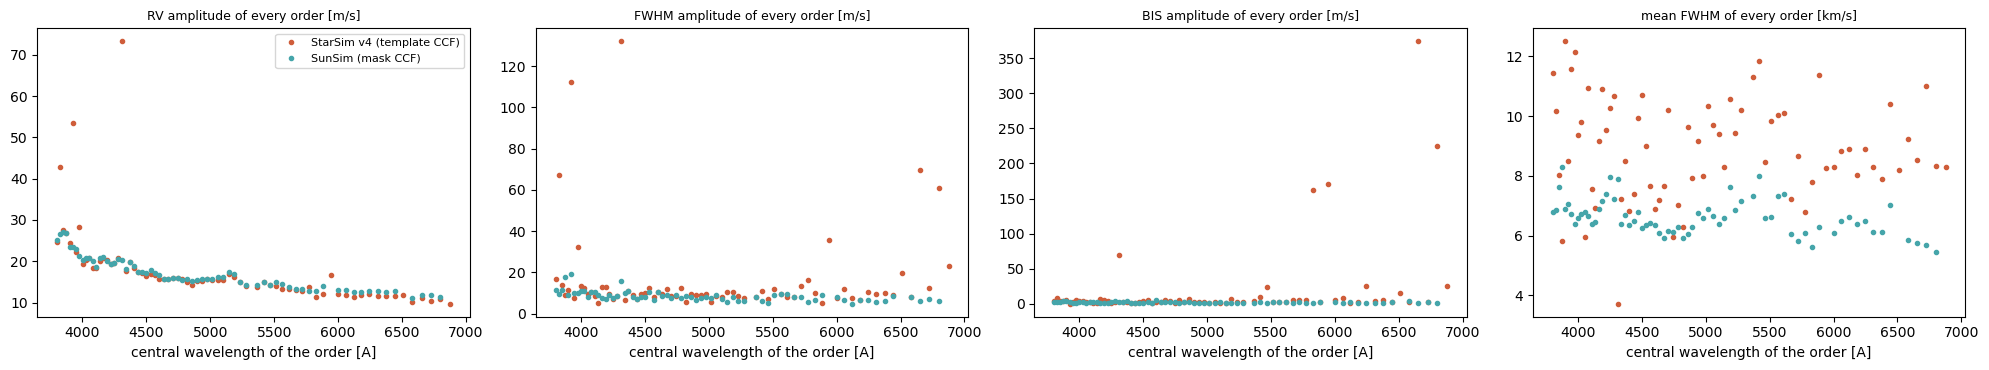

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


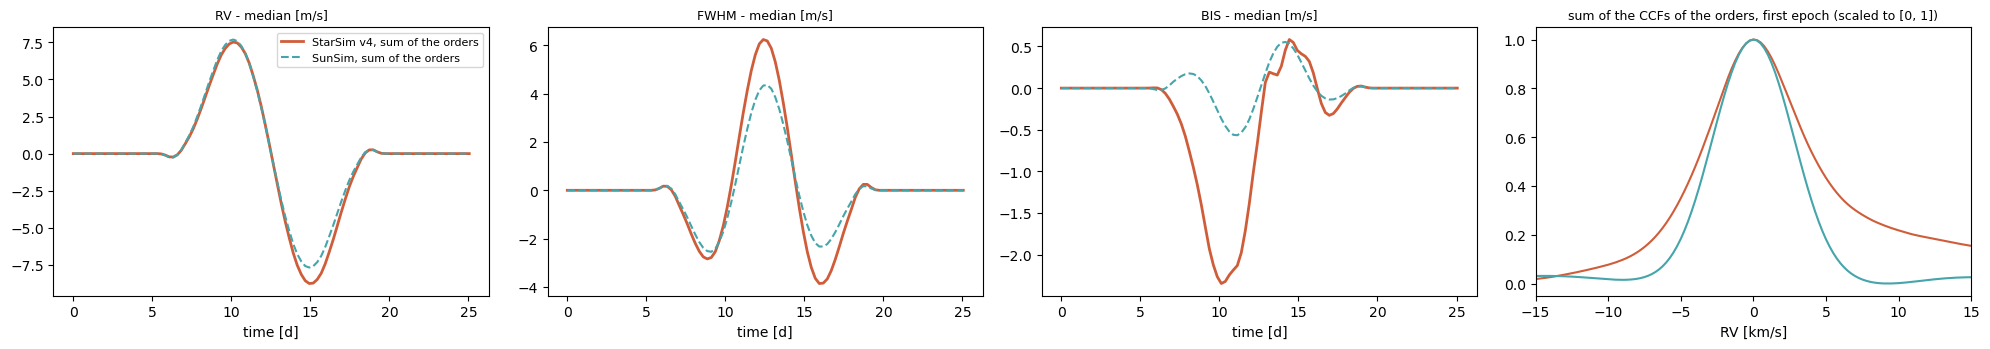

,orders with a CCF,sum of the orders: FWHM quiet [km/s],RV amplitude [m/s],FWHM amplitude [m/s],BIS amplitude [m/s],median RV amplitude of the orders [m/s]
version,,,,,,
StarSim v4 (template),72,8.22,16.3,10.1,2.93,15.7
SunSim (mask),69,6.43,15.4,6.9,1.12,15.9


In [22]:
from types import SimpleNamespace
colors = {'StarSim v4': '#cf5d3a', 'optimized': '#45a5aa'}       # as in section 4 (the section can run alone)
v4o = [r for r in echelle_runs if r['variant'] == 'StarSim v4, echelle' and 'outputs' in r][0]['outputs']
sso = [r for r in echelle_runs if r['variant'] == 'SunSim, order by order' and 'outputs' in r][0]['outputs']
pro = per_order_run['outputs']
t = v4o['times']
centre = order_wav.mean(axis=1)                 # central wavelength of every order [A]

# 1. every order: amplitude (max - min over the rotation) of the RV, FWHM and BIS, and the mean FWHM of the order
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
for ax, key, label in zip(axes, ('rv', 'fwhm', 'bis'), ('RV', 'FWHM', 'BIS')):
    a = np.ptp(v4o['%s_orders' % key], axis=0)
    b = np.ptp(pro['%s_orders' % key], axis=0)
    ax.plot(centre, a, 'o', ms=3, color=colors['StarSim v4'], label='StarSim v4 (template CCF)')
    ax.plot(centre, b, 'o', ms=3, color=colors['optimized'], label='SunSim (mask CCF)')
    ax.set_xlabel('central wavelength of the order [A]')
    ax.set_title('%s amplitude of every order [m/s]' % label, fontsize=9)
axes[3].plot(centre, np.nanmean(v4o['fwhm_orders'], axis=0) / 1000, 'o', ms=3, color=colors['StarSim v4'])
axes[3].plot(centre, np.nanmean(pro['fwhm_orders'], axis=0) / 1000, 'o', ms=3, color=colors['optimized'])
axes[3].set_xlabel('central wavelength of the order [A]')
axes[3].set_title('mean FWHM of every order [km/s]', fontsize=9)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# 2. all the orders together: the sum of the CCFs of the orders, fitted with the same fit (SunSim's) for both codes
vsini = 2 * np.pi * star['radius'] * 6.957e8 / (star['P_rot'] * 86400)      # [m/s], equator-on: initial guess of the fit
fit = lambda rv, ccf: sunsim.StarSim.compute_ccf_params(SimpleNamespace(vsini=vsini), rv=rv, ccf=ccf)
v4_fit = fit(v4o['ccf_rv'], v4o['ccf_sum'])
ss_fit = fit(sso['ccf_rv'], sso['ccf'])
fig, axes = plt.subplots(1, 4, figsize=(20, 3.6))
for ax, i, label in zip(axes, (0, 2, 3), ('RV - median [m/s]', 'FWHM - median [m/s]', 'BIS - median [m/s]')):
    ax.plot(t, v4_fit[i] - np.median(v4_fit[i]), '-', lw=2, color=colors['StarSim v4'], label='StarSim v4, sum of the orders')
    ax.plot(t, ss_fit[i] - np.median(ss_fit[i]), '--', lw=1.5, color=colors['optimized'], label='SunSim, sum of the orders')
    ax.set_title(label, fontsize=9)
    ax.set_xlabel('time [d]')
for c, rv, ccf, name in ((colors['StarSim v4'], v4o['ccf_rv'], v4o['ccf_sum'][0], 'StarSim v4'),
                         (colors['optimized'], sso['ccf_rv'], sso['ccf'][0], 'SunSim')):
    q = (ccf - ccf.min()) / (ccf.max() - ccf.min())
    axes[3].plot(np.asarray(rv) / 1000, q, color=c, label=name)
axes[3].set_xlim(-15, 15)
axes[3].set_xlabel('RV [km/s]')
axes[3].set_title('sum of the CCFs of the orders, first epoch (scaled to [0, 1])', fontsize=9)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

summary_rows = []
for name, f, per in (('StarSim v4 (template)', v4_fit, v4o), ('SunSim (mask)', ss_fit, pro)):
    summary_rows.append({'version': name,
                         'orders with a CCF': int(np.sum(np.all(np.isfinite(per['rv_orders']), axis=0))),
                         'sum of the orders: FWHM quiet [km/s]': f[2][0] / 1000,
                         'RV amplitude [m/s]': np.ptp(f[0]), 'FWHM amplitude [m/s]': np.ptp(f[2]),
                         'BIS amplitude [m/s]': np.ptp(f[3]),
                         'median RV amplitude of the orders [m/s]': np.nanmedian(np.ptp(per['rv_orders'], axis=0))})
pd.DataFrame(summary_rows).set_index('version')

**Results** (medians of 3 processes; reference case, 50 rings).

* **Time.** One simulation of the 72 orders takes **27 s with StarSim v4** (it reads the Phoenix models, flattens, degrades and simulates every order separately) and **1.2 s with SunSim** (22× faster); a new session 28 s vs 2.6 s. SunSim keeps the CCF grids of the orders: every other simulation with them (other regions, epochs, planets) takes **0.011 s** (~2400× less than StarSim v4, which redoes all the orders in every `simulate_forward`).
* **RAM.** StarSim v4 needs less: 0.57 GB vs 0.74 GB. It handles one order at a time (4096 pixels), while SunSim degrades the three whole spectra at once (~390 000 pixels each: spline and FFT) before cutting them into orders.
* **Order by order** (first figure; SunSim: every order simulated alone, with the brightness of the rings in the range of the order, as StarSim v4). The RV amplitude of the region decreases from the blue to the red orders in both codes (20 → 12 m/s: the contrast of the spot decreases with the wavelength; median over the orders 15.7 m/s in StarSim v4, 15.9 m/s in SunSim), and the two codes agree order by order (median difference 0.55 m/s, correlation 0.94, in the previous run at 20 rings), although StarSim v4 cross-correlates with the synthetic spectrum and SunSim with the mask. The FWHM of the orders differs (6-8 km/s with the mask, 6-12 km/s with the template, which depends on the lines of every order), and in a few orders (3826, 4310, 5829, 6375, 6652, 6800 Å in the previous run) the fit of the template CCF of StarSim v4 fails (RV amplitude up to 73 m/s, BIS up to 370 m/s). SunSim has no CCF in 3 red orders, which have no line of the mask.
* **All the orders together** (second figure; both sums fitted with the same fit). The RV agrees (amplitude 16.3 vs 15.4 m/s), the FWHM and the BIS less (10.1 vs 6.9 m/s, 2.9 vs 1.1 m/s): the sum of the template CCFs of StarSim v4 is wider (8.2 vs 6.4 km/s) and asymmetric (a long red wing), so its shape changes differently. StarSim v4 does not combine the orders itself: this sum is made here from its CCFs of every order.
* **Flattening, efficiency.** Both codes normalise the CCF of every order, so a factor common to a whole order disappears: the efficiency (here, SunSim: ≤ 0.002 m/s on the RV, FWHM and BIS) and the flattening of the spectra (≤ 0.001 m/s) change nothing, the blaze only through its shape inside the order (0.015 m/s). Only the normalisation of the CCF (`normalization` / `flag_normalise_ccf`) changes the signals (1.1 m/s on the RV here).
* **Not the same treatment** (see above): the CCF (template vs mask), the resampling on the orders (linear interpolation vs flux-conserving), the order of the operations (StarSim v4 multiplies by the response before degrading the resolution, on the pixels of the order; SunSim degrades the whole spectrum first), the flattening (per order vs whole spectrum), and the brightness of the rings: StarSim v4 uses the brightness in the range of every order; SunSim's `CCF_grid` scales the sum of the orders by one brightness per ring (`mu_ratio`, here in the whole band), so in SunSim's sum of the orders a spot has the same contrast in the blue and in the red orders (the per-order runs above use the brightness of every order).

## 12. Clean up

The temporary folder holds the scripts, the configuration files and the outputs of the runs.

In [23]:
shutil.rmtree(work_dir, ignore_errors=True)
print('deleted', work_dir)

deleted /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim4_gzd8g7dq
